# 🌦️ Previsão do Tempo em Macau com Machine Learning
### CSAI3121 – Machine Learning and Intelligent Data Analysis · Group Project

**Equipe:** Thiago Honorato Ferreira (P262742-1) · Marcelo Oliveira (P262739-4) · João Vitor Konrad (P262740-2)

---

## O que este notebook faz

Este notebook implementa **de ponta a ponta** o sistema pedido na especificação do projeto:

| Tarefa | Tipo | Alvo (target) | Horizonte |
|---|---|---|---|
| **1** | Regressão | Temperatura **máxima** e **mínima** do dia seguinte (°C) | t + 1 dia |
| **2** | Classificação | **Condição do tempo** do dia seguinte (Clear / Partly Cloudy / Cloudy / Rain) | t + 1 dia |

Para cada tarefa comparamos **1 baseline + 3 modelos de ML**, ajustamos (tuning) o melhor,
testamos um **ensemble** (extensão/inovação) e avaliamos o modelo final **uma única vez** no conjunto de teste.

## Roteiro

1. Configuração e bibliotecas
2. Coleta de dados (Visual Crossing ou Open‑Meteo)
3. Qualidade e limpeza dos dados
4. Mapeamento das condições do tempo → 4 classes
5. Análise Exploratória (EDA)
6. Engenharia de features (lags, médias móveis, sazonalidade…)
7. Divisão cronológica treino / validação / teste
8. **Tarefa 1 – Regressão** (baseline, modelos, tuning, ensemble, teste, importância)
9. **Tarefa 2 – Classificação** (baseline, modelos, tuning, ensemble, teste, importância)
10. Resumo final, limitações e trabalhos futuros

## Como rodar
* Abra no Jupyter / VS Code e execute **Kernel → Restart & Run All**. Nenhuma intervenção manual é necessária.
* Na primeira execução os dados são baixados da internet e salvos em `data/raw/`. Nas próximas execuções o CSV salvo é reutilizado (reprodutibilidade total, mesmo offline).
* Tempo total de execução: ~3–6 minutos num notebook comum.

> 💡 **Dica de leitura (tutor):** cada célula de código começa com um comentário dizendo *o que* ela faz, e cada função tem uma *docstring* explicando **responsabilidade, entradas e saídas**. As células em texto explicam o *porquê* de cada decisão.

---
## 1. Configuração do ambiente

Aqui importamos as bibliotecas e definimos **constantes globais** (semente aleatória, caminhos, datas da divisão).
Centralizar as configurações no topo é uma boa prática: se quisermos mudar a cidade ou o período, mudamos só aqui.

* `pandas` / `numpy` → manipulação de dados
* `matplotlib` / `seaborn` → gráficos
* `scikit-learn` → modelos, pipelines, validação e métricas
* `requests` → download dos dados via API

In [1]:
# ---------------------------------------------------------------
# 1.1 Importação das bibliotecas
# ---------------------------------------------------------------
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from scipy.stats import pearsonr, loguniform, randint

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier)
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, balanced_accuracy_score, f1_score,
                             precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, brier_score_loss)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
print("Versões -> pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

Versões -> pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0


In [2]:
# ---------------------------------------------------------------
# 1.2 Constantes globais do projeto
# ---------------------------------------------------------------
SEED = 42                      # semente fixa -> resultados reprodutíveis
np.random.seed(SEED)

# Local escolhido: Macau (coordenadas aproximadas da península)
LOCATION_NAME = "Macau"
LATITUDE, LONGITUDE = 22.1987, 113.5439
TIMEZONE = "Asia/Macau"

# Período: 12 anos completos (> 4000 registros, acima do mínimo de 3000 / 10 anos exigido)
START_DATE, END_DATE = "2014-01-01", "2025-12-31"

# Divisão cronológica (pela DATA DO ALVO, ou seja, o dia que está sendo previsto)
TRAIN_END = "2021-12-31"       # treino:    2014 – 2021 (8 anos)
VAL_END   = "2023-12-31"       # validação: 2022 – 2023 (2 anos)
                               # teste:     2024 – 2025 (2 anos)

# Estrutura de pastas (criadas automaticamente)
BASE_DIR      = Path.cwd()
RAW_DIR       = BASE_DIR / "data" / "raw"
VC_DIR        = RAW_DIR / "visualcrossing"   # CSVs do Visual Crossing (pode ser dividido em várias partes)
PROCESSED_DIR = BASE_DIR / "data" / "processed"
FIG_DIR       = BASE_DIR / "figures"
RESULTS_DIR   = BASE_DIR / "results"
MODELS_DIR    = BASE_DIR / "models"
for d in [RAW_DIR, VC_DIR, PROCESSED_DIR, FIG_DIR, RESULTS_DIR, MODELS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Arquivos de dados brutos
VC_RAW_FILE = RAW_DIR / "macau_visualcrossing_raw.csv"   # se você baixou do Visual Crossing, coloque aqui
MIN_RECORDS = 3000                                        # mínimo exigido pela especificação (>= 3000 dias)
OM_RAW_FILE = RAW_DIR / "macau_openmeteo_raw.csv"        # fallback automático (Open-Meteo)

# Chave da API do Visual Crossing (opcional). Ex.: no terminal -> export VC_API_KEY="sua_chave"
VC_API_KEY = os.environ.get("VC_API_KEY", "")

# Ordem fixa das classes (usada em todos os gráficos e matrizes de confusão)
CLASSES = ["Clear", "Partly Cloudy", "Cloudy", "Rain"]

# Paleta categórica (validada para daltonismo): mesma cor = mesma classe em todo o notebook
CLASS_COLORS = {"Clear": "#2a78d6", "Partly Cloudy": "#eda100", "Cloudy": "#1baf7a", "Rain": "#eb6834"}
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"

# Estilo dos gráficos: grade discreta, linhas finas
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 1.5, "grid.alpha": 0.4})

def save_fig(name):
    '''Salva a figura atual em figures/<name>.png (útil para colocar no relatório).'''
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print("Pasta base:", BASE_DIR)

Pasta base: /Users/thiagohonoratoferreira/Desktop/project_update


---
## 2. Coleta de dados

A especificação pede o **Visual Crossing Weather Query Builder**. Ele exige cadastro e o plano gratuito
limita a **1000 registros/dia** – baixar 12 anos (4383 dias) exige dividir o download entre os membros
ao longo de alguns dias. Por isso o notebook foi escrito para funcionar com **duas fontes**, nesta ordem de prioridade:

1. **CSV(s) do Visual Crossing** salvos em `data/raw/macau_visualcrossing_raw.csv` **ou** vários arquivos em `data/raw/visualcrossing/`
   (útil porque o plano gratuito limita 1000 registros/dia: cada membro baixa alguns anos e todos os arquivos são juntados automaticamente);
2. **Download via API do Visual Crossing**, se a variável de ambiente `VC_API_KEY` existir (baixa ano a ano e guarda cada pedaço em cache, então pode ser completado ao longo de vários dias/chaves);
3. **Fallback: Open‑Meteo Historical API** (reanálise ERA5, gratuita e sem chave) – garante que o notebook **sempre roda**.

**Como baixar o histórico no Visual Crossing (Query Builder):** digite `Macau`; em *Date range* escolha **Date range** (não "Next 15 days", que é a *previsão*)
e informe as datas, por exemplo `2014-01-01` a `2016-12-31` (≈1000 dias por pessoa/dia); em *Units* escolha **Metric (°C, km/h, mm)**; em *Include* deixe **Days**;
clique em **Download → CSV** e salve em `data/raw/visualcrossing/`. Repita para 2017–2019, 2020–2022 e 2023–2025.
O notebook **valida** os arquivos: se eles cobrirem menos de 3000 dias (ex.: só a previsão de 15 dias), ele avisa e usa o Open‑Meteo.
Se os dados vierem em unidades americanas (°F, polegadas, mph), eles são **convertidos automaticamente** para o sistema métrico.

Para que o resto do código seja **idêntico** nas duas fontes, os dados do Open‑Meteo são **renomeados para o
mesmo esquema de colunas do Visual Crossing** (`tempmax`, `tempmin`, `humidity`, `conditions`, …).

| Coluna (esquema VC) | Significado | Unidade |
|---|---|---|
| `tempmax`, `tempmin`, `temp` | temperatura máx., mín. e média do dia | °C |
| `feelslikemax`, `feelslikemin` | sensação térmica máx./mín. | °C |
| `dew` | ponto de orvalho médio | °C |
| `humidity` | umidade relativa média | % |
| `precip` | precipitação total | mm |
| `precipcover` | % das horas do dia com chuva | % |
| `windspeed`, `windgust` | vento máximo e rajada máxima | km/h |
| `winddir` | direção dominante do vento | graus |
| `sealevelpressure` | pressão ao nível do mar | hPa |
| `cloudcover` | cobertura de nuvens média | % |
| `solarenergy` | energia solar diária | MJ/m² |
| `conditions` | rótulo textual da condição do tempo | texto |

In [3]:
# ---------------------------------------------------------------
# 2.1 Funções de download / carga dos dados brutos
# ---------------------------------------------------------------

# Colunas numéricas que usaremos (presentes nas duas fontes)
NUMERIC_COLS = ["tempmax", "tempmin", "temp", "feelslikemax", "feelslikemin", "dew", "humidity",
                "precip", "precipcover", "windgust", "windspeed", "winddir",
                "sealevelpressure", "cloudcover", "solarenergy"]


def download_visual_crossing(api_key, start=START_DATE, end=END_DATE, location=LOCATION_NAME):
    '''
    Responsabilidade: baixar dados DIÁRIOS do Visual Crossing (Timeline API), ano a ano.
    - Cada ano é salvo num arquivo de cache (data/raw/vc_chunks/<ano>.csv). Assim, se o limite
      diário de 1000 registros estourar, basta rodar de novo no dia seguinte (ou com a chave de
      outro colega) que só os anos que faltam são baixados.
    Retorna: DataFrame com todos os anos concatenados, ou None se faltar algum ano.
    '''
    chunk_dir = RAW_DIR / "vc_chunks"
    chunk_dir.mkdir(exist_ok=True)
    base = "https://weather.visualcrossing.com/VisualCrossingWebServices/rest/services/timeline"
    years = range(pd.Timestamp(start).year, pd.Timestamp(end).year + 1)
    for y in years:
        f = chunk_dir / f"{y}.csv"
        if f.exists():
            continue                                    # já baixado -> pula
        url = f"{base}/{location}/{y}-01-01/{y}-12-31"
        params = dict(unitGroup="metric", include="days", contentType="csv", key=api_key)
        r = requests.get(url, params=params, timeout=120)
        if r.status_code != 200:
            print(f"  Ano {y}: falhou (HTTP {r.status_code}) -> provavelmente limite diário. Rode de novo amanhã.")
            return None
        f.write_text(r.text, encoding="utf-8")
        print(f"  Ano {y}: OK")
        time.sleep(1)
    df = pd.concat([pd.read_csv(chunk_dir / f"{y}.csv") for y in years], ignore_index=True)
    return df


def download_open_meteo(start=START_DATE, end=END_DATE):
    '''
    Responsabilidade: baixar dados diários históricos (reanálise ERA5) da Open-Meteo Archive API
    e convertê-los para o ESQUEMA DE COLUNAS DO VISUAL CROSSING.
    A Open-Meteo não fornece um rótulo textual de condição do tempo, então ele é DERIVADO de forma
    transparente a partir da precipitação e da cobertura de nuvens (ver make_vc_style_conditions).
    '''
    daily_vars = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
                  "apparent_temperature_max", "apparent_temperature_min", "dew_point_2m_mean",
                  "relative_humidity_2m_mean", "precipitation_sum", "precipitation_hours",
                  "wind_gusts_10m_max", "wind_speed_10m_max", "wind_direction_10m_dominant",
                  "pressure_msl_mean", "cloud_cover_mean", "shortwave_radiation_sum"]
    params = dict(latitude=LATITUDE, longitude=LONGITUDE, start_date=start, end_date=end,
                  daily=",".join(daily_vars), timezone=TIMEZONE)
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=180)
    r.raise_for_status()
    raw = pd.DataFrame(r.json()["daily"])

    # Renomeia para o esquema do Visual Crossing
    rename = {"time": "datetime", "temperature_2m_max": "tempmax", "temperature_2m_min": "tempmin",
              "temperature_2m_mean": "temp", "apparent_temperature_max": "feelslikemax",
              "apparent_temperature_min": "feelslikemin", "dew_point_2m_mean": "dew",
              "relative_humidity_2m_mean": "humidity", "precipitation_sum": "precip",
              "wind_gusts_10m_max": "windgust", "wind_speed_10m_max": "windspeed",
              "wind_direction_10m_dominant": "winddir", "pressure_msl_mean": "sealevelpressure",
              "cloud_cover_mean": "cloudcover", "shortwave_radiation_sum": "solarenergy"}
    df = raw.rename(columns=rename)
    # precipcover no VC = % do dia com chuva -> horas de chuva / 24 * 100
    df["precipcover"] = (df.pop("precipitation_hours") / 24 * 100).round(2)
    df.insert(0, "name", LOCATION_NAME)
    df["conditions"] = make_vc_style_conditions(df["precip"], df["cloudcover"])
    return df


def make_vc_style_conditions(precip, cloudcover, rain_mm=1.0, overcast=70, partly=30):
    '''
    Responsabilidade: criar um rótulo textual NO MESMO ESTILO do Visual Crossing
    ("Clear", "Partially cloudy", "Overcast", "Rain, Overcast", ...) a partir de variáveis numéricas.
    Regras (documentadas e justificadas na Seção 4):
      * precipitação >= 1 mm  -> contém "Rain"  (limiar da OMM para "dia de chuva")
      * cobertura de nuvens >= 70%  -> "Overcast"         (~6 a 8 oktas)
      * 30% <= nuvens < 70%         -> "Partially cloudy" (~3 a 5 oktas)
      * nuvens < 30%                -> "Clear"            (~0 a 2 oktas)
    '''
    sky = np.where(cloudcover >= overcast, "Overcast",
          np.where(cloudcover >= partly, "Partially cloudy", "Clear"))
    return np.where(precip >= rain_mm, "Rain, " + sky, sky)


def to_metric(df):
    '''
    Responsabilidade: detectar se o CSV do Visual Crossing veio em unidades americanas (US) e converter para métrico.
    Heurística segura: a mediana da temperatura máxima em °C nunca passa de ~45 em lugar nenhum do planeta;
    em °F, Macau fica em torno de 80. Conversões: °F->°C, polegadas->mm, mph->km/h, milhas->km.
    '''
    df = df.copy()
    if pd.to_numeric(df["tempmax"], errors="coerce").median() <= 45:
        return df                                                # já está em °C
    print("  Unidades americanas detectadas (°F / in / mph) -> convertendo para o sistema métrico.")
    for c in ["tempmax", "tempmin", "temp", "feelslikemax", "feelslikemin", "feelslike", "dew"]:
        if c in df: df[c] = (pd.to_numeric(df[c], errors="coerce") - 32) * 5 / 9
    for c in ["precip", "snow", "snowdepth"]:
        if c in df: df[c] = pd.to_numeric(df[c], errors="coerce") * 25.4
    for c in ["windgust", "windspeed", "visibility"]:
        if c in df: df[c] = pd.to_numeric(df[c], errors="coerce") * 1.609344
    return df


def read_visual_crossing_files():
    '''
    Responsabilidade: ler TODOS os CSVs do Visual Crossing disponíveis (arquivo único e/ou partes em
    data/raw/visualcrossing/), juntar, remover datas repetidas e padronizar as unidades.
    Retorna None se não houver nenhum arquivo.
    '''
    files = ([VC_RAW_FILE] if VC_RAW_FILE.exists() else []) + sorted(VC_DIR.glob("*.csv"))
    if not files:
        return None
    parts = []
    for f in files:
        part = to_metric(pd.read_csv(f))
        print(f"  {f.name}: {len(part)} linhas ({part['datetime'].min()} -> {part['datetime'].max()})")
        parts.append(part)
    df = pd.concat(parts, ignore_index=True).drop_duplicates("datetime").sort_values("datetime")
    return df.reset_index(drop=True)


def validate_history(df):
    '''
    Responsabilidade: verificar se os dados são um HISTÓRICO longo o bastante para o projeto.
    Retorna (ok, motivo). Detecta o erro comum de baixar a PREVISÃO de 15 dias em vez do histórico.
    '''
    dates = pd.to_datetime(df["datetime"])
    if dates.max() > pd.Timestamp.today().normalize() + pd.Timedelta(days=1):
        return False, (f"o arquivo contém datas FUTURAS (até {dates.max().date()}): é a PREVISÃO do tempo, "
                       "não o histórico. No Query Builder, escolha 'Date range' com datas passadas.")
    if len(df) < MIN_RECORDS:
        return False, (f"só {len(df)} dias ({dates.min().date()} -> {dates.max().date()}); "
                       f"são necessários pelo menos {MIN_RECORDS}. Baixe os anos que faltam em data/raw/visualcrossing/.")
    return True, "ok"


def load_raw_data():
    '''
    Responsabilidade: decidir QUAL fonte usar (ordem de prioridade descrita acima),
    salvar o CSV bruto em data/raw/ e devolver (DataFrame, nome_da_fonte).
    '''
    vc = read_visual_crossing_files()
    if vc is None and VC_API_KEY:
        print("Baixando do Visual Crossing (API)...")
        vc = download_visual_crossing(VC_API_KEY)
        vc = to_metric(vc) if vc is not None else None
    if vc is not None:
        ok, motivo = validate_history(vc)
        if ok:
            print(f"Usando dados do Visual Crossing: {len(vc)} dias.")
            return vc, "Visual Crossing"
        print(f"\n⚠️  Dados do Visual Crossing NÃO utilizados: {motivo}\n   -> usando Open-Meteo por enquanto.\n")
    if OM_RAW_FILE.exists():
        print("Usando CSV do Open-Meteo já salvo:", OM_RAW_FILE.name)
        return pd.read_csv(OM_RAW_FILE), "Open-Meteo (ERA5)"
    print("Baixando do Open-Meteo (pode levar alguns segundos)...")
    df = download_open_meteo()
    df.to_csv(OM_RAW_FILE, index=False)
    return df, "Open-Meteo (ERA5)"

In [4]:
# ---------------------------------------------------------------
# 2.2 Carrega os dados brutos e documenta a fonte
# ---------------------------------------------------------------
raw_df, DATA_SOURCE = load_raw_data()

print(f"\nFonte: {DATA_SOURCE}")
print(f"Formato: {raw_df.shape[0]} linhas x {raw_df.shape[1]} colunas")
print(f"Período: {raw_df['datetime'].min()} -> {raw_df['datetime'].max()}")

# Documentação do dataset (exigida nos entregáveis): local, período, variáveis, como reproduzir
readme = f'''# Dados do projeto - Previsão do tempo em {LOCATION_NAME}
* Fonte utilizada: {DATA_SOURCE}
* Local: {LOCATION_NAME} (lat {LATITUDE}, lon {LONGITUDE}), fuso {TIMEZONE}
* Período: {START_DATE} a {END_DATE} (dados diários, {raw_df.shape[0]} registros)
* Variáveis: {", ".join(c for c in NUMERIC_COLS if c in raw_df.columns)}, conditions
* Reproduzir: rode o notebook weather_prediction_macau.ipynb. Ele lê data/raw/*.csv se existir;
  senão baixa via Visual Crossing (export VC_API_KEY=...) ou Open-Meteo Archive API (sem chave):
  https://archive-api.open-meteo.com/v1/archive?latitude={LATITUDE}&longitude={LONGITUDE}&start_date={START_DATE}&end_date={END_DATE}&timezone={TIMEZONE}&daily=...
* Visual Crossing (manual): https://www.visualcrossing.com/weather-query-builder/ -> Macau,
  Date range (datas passadas, ~1000 dias por download), Metric, Days, CSV -> salvar em data/raw/visualcrossing/
'''
(BASE_DIR / "data" / "README_data.md").write_text(readme, encoding="utf-8")
raw_df.head()

Usando CSV do Open-Meteo já salvo: macau_openmeteo_raw.csv

Fonte: Open-Meteo (ERA5)
Formato: 4383 linhas x 18 colunas
Período: 2014-01-01 -> 2025-12-31


,name,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,dew,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,solarenergy,precipcover,conditions
0,Macau,2014-01-01,18.2,11.4,14.3,16.7,8.8,6.3,60,0.0,23.8,11.6,43,1019.2,0,16.95,0.0,Clear
1,Macau,2014-01-02,19.6,11.3,15.7,20.5,10.1,12.7,83,0.0,20.2,10.0,88,1016.6,12,15.90,0.0,Clear
2,Macau,2014-01-03,21.6,15.9,18.3,22.9,15.8,14.1,77,0.0,21.6,10.5,347,1015.9,34,15.76,0.0,Partially cloudy
3,Macau,2014-01-04,20.4,14.6,17.1,17.6,11.4,8.9,59,0.0,39.2,22.4,1,1018.1,1,16.59,0.0,Clear
4,Macau,2014-01-05,18.6,13.3,15.8,17.2,10.1,7.9,60,0.0,32.0,16.5,69,1018.5,1,16.75,0.0,Clear


---
## 3. Qualidade e limpeza dos dados

Antes de modelar, um analista **sempre audita os dados**. Verificamos:

* **Duplicatas** – a mesma data aparecendo duas vezes;
* **Datas faltantes** – buracos na série temporal (os lags dependem de dias consecutivos!);
* **Valores ausentes (NaN)** por coluna;
* **Valores inválidos** – fisicamente impossíveis (ex.: umidade > 100%, Tmax < Tmin, precipitação negativa);
* **Outliers** – valores extremos. ⚠️ Em meteorologia, extremos geralmente são **reais** (tufões!), então
  nós os **investigamos** em vez de apagá‑los cegamente.

In [5]:
# ---------------------------------------------------------------
# 3.1 Auditoria de qualidade
# ---------------------------------------------------------------

# Limites físicos plausíveis para Macau (usados para detectar valores inválidos)
VALID_RANGES = {"tempmax": (-5, 45), "tempmin": (-10, 40), "temp": (-10, 42), "feelslikemax": (-15, 60),
                "feelslikemin": (-20, 50), "dew": (-30, 35), "humidity": (0, 100), "precip": (0, 1000),
                "precipcover": (0, 100), "windgust": (0, 300), "windspeed": (0, 250), "winddir": (0, 360),
                "sealevelpressure": (900, 1060), "cloudcover": (0, 100), "solarenergy": (0, 45)}


def data_quality_report(df):
    '''
    Responsabilidade: produzir um diagnóstico da qualidade dos dados SEM alterá-los.
    Imprime duplicatas, datas faltantes, Tmax<Tmin e devolve uma tabela por coluna
    com nº de NaN e nº de valores fora do intervalo físico.
    '''
    dates = pd.to_datetime(df["datetime"])
    full_range = pd.date_range(dates.min(), dates.max(), freq="D")
    print(f"Datas duplicadas      : {dates.duplicated().sum()}")
    print(f"Datas faltantes       : {len(full_range.difference(dates))}")
    print(f"Linhas com Tmax < Tmin: {(df['tempmax'] < df['tempmin']).sum()}")
    rows = []
    for col in NUMERIC_COLS:
        if col not in df.columns:
            rows.append({"coluna": col, "NaN": len(df), "fora_do_intervalo": 0, "min": np.nan, "max": np.nan})
            continue
        lo, hi = VALID_RANGES[col]
        s = pd.to_numeric(df[col], errors="coerce")
        rows.append({"coluna": col, "NaN": int(s.isna().sum()),
                     "fora_do_intervalo": int(((s < lo) | (s > hi)).sum()),
                     "min": s.min(), "max": s.max()})
    return pd.DataFrame(rows).set_index("coluna")


data_quality_report(raw_df)

Datas duplicadas      : 0
Datas faltantes       : 0
Linhas com Tmax < Tmin: 0


,NaN,fora_do_intervalo,min,max
coluna,,,,
tempmax,0,0,6.50,36.10
tempmin,0,0,3.60,29.50
temp,0,0,4.90,31.50
feelslikemax,0,0,-0.90,44.00
feelslikemin,0,0,-3.90,35.60
dew,0,0,-5.80,27.70
humidity,0,0,32.00,97.00
precip,0,0,0.00,195.80
precipcover,0,0,0.00,100.00


In [6]:
# ---------------------------------------------------------------
# 3.2 Limpeza
# ---------------------------------------------------------------
def clean_data(df):
    '''
    Responsabilidade: devolver um DataFrame LIMPO, indexado por data diária contínua.
    Passos (cada um justificado):
      1. Converte 'datetime' para data e ordena cronologicamente.
      2. Remove datas duplicadas (mantém a primeira ocorrência).
      3. Reindexa para TODOS os dias do período -> datas faltantes viram linhas com NaN
         (essencial para que lag-1 signifique realmente "ontem").
      4. Valores fisicamente impossíveis -> NaN (tratados como ausentes).
      5. Tmax < Tmin -> troca os dois valores (erro de digitação/ordem).
      6. Preenche NaN numéricos por INTERPOLAÇÃO TEMPORAL (limite de 3 dias seguidos);
         precipitação ausente -> 0 (ausência de registro de chuva). Para o rótulo 'conditions',
         usamos o valor do dia anterior (forward-fill). Interpolação só usa vizinhos próximos,
         e é feita ANTES da criação dos alvos, sem mistura entre conjuntos -> risco de vazamento desprezível.
      7. Colunas com mais de 5% de valores ainda ausentes (ex.: rajada de vento sem registro em anos antigos
         do Visual Crossing) são DESCARTADAS, para não perdermos centenas de dias por causa de uma variável.
      8. Remove linhas que ainda tenham NaN (buracos > 3 dias).
    '''
    df = df.copy()
    df["datetime"] = pd.to_datetime(df["datetime"])
    df = df.sort_values("datetime").drop_duplicates("datetime", keep="first")          # passos 1-2
    df = df.set_index("datetime").asfreq("D")                                           # passo 3
    df.index.name = "date"
    keep = [c for c in NUMERIC_COLS + ["conditions"] if c in df.columns]
    df = df[keep]
    for col in [c for c in NUMERIC_COLS if c in df.columns]:                            # passo 4
        df[col] = pd.to_numeric(df[col], errors="coerce")
        lo, hi = VALID_RANGES[col]
        df.loc[(df[col] < lo) | (df[col] > hi), col] = np.nan
    swap = df["tempmax"] < df["tempmin"]                                                # passo 5
    df.loc[swap, ["tempmax", "tempmin"]] = df.loc[swap, ["tempmin", "tempmax"]].values
    df["precip"] = df["precip"].fillna(0)                                               # passo 6
    other = [c for c in NUMERIC_COLS if c != "precip" and c in df.columns]
    df[other] = df[other].interpolate(method="time", limit=3, limit_direction="both")
    df["conditions"] = df["conditions"].ffill()
    sparse = [c for c in other if df[c].isna().mean() > 0.05 and c not in ("tempmax", "tempmin")]
    if sparse:                                                                          # passo 7
        print("Colunas descartadas por excesso de valores ausentes:", sparse)
        df = df.drop(columns=sparse)
    n_before = len(df)
    df = df.dropna()                                                                    # passo 8
    print(f"Linhas removidas por buracos longos: {n_before - len(df)}")
    return df


df = clean_data(raw_df)
NUM_COLS = [c for c in NUMERIC_COLS if c in df.columns]     # variáveis numéricas efetivamente disponíveis
print("Formato após limpeza:", df.shape)
print("NaN restantes:", int(df.isna().sum().sum()))
df.head()

Linhas removidas por buracos longos: 0
Formato após limpeza: (4383, 16)
NaN restantes: 0


,tempmax,tempmin,temp,feelslikemax,feelslikemin,dew,humidity,precip,precipcover,windgust,windspeed,winddir,sealevelpressure,cloudcover,solarenergy,conditions
date,,,,,,,,,,,,,,,,
2014-01-01,18.2,11.4,14.3,16.7,8.8,6.3,60.0,0.0,0.0,23.8,11.6,43.0,1019.2,0.0,16.95,Clear
2014-01-02,19.6,11.3,15.7,20.5,10.1,12.7,83.0,0.0,0.0,20.2,10.0,88.0,1016.6,12.0,15.90,Clear
2014-01-03,21.6,15.9,18.3,22.9,15.8,14.1,77.0,0.0,0.0,21.6,10.5,347.0,1015.9,34.0,15.76,Partially cloudy
2014-01-04,20.4,14.6,17.1,17.6,11.4,8.9,59.0,0.0,0.0,39.2,22.4,1.0,1018.1,1.0,16.59,Clear
2014-01-05,18.6,13.3,15.8,17.2,10.1,7.9,60.0,0.0,0.0,32.0,16.5,69.0,1018.5,1.0,16.75,Clear


In [7]:
# ---------------------------------------------------------------
# 3.3 Investigação de outliers (método do IQR) - investigar, não apagar
# ---------------------------------------------------------------
def iqr_outlier_summary(df, cols, k=3.0):
    '''
    Responsabilidade: contar valores além de Q3 + k*IQR ou abaixo de Q1 - k*IQR.
    Usamos k=3 ("outliers extremos"). Retorna tabela com contagens e limites.
    '''
    out = []
    for c in cols:
        q1, q3 = df[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - k * iqr, q3 + k * iqr
        out.append({"coluna": c, "limite_inf": round(lo, 1), "limite_sup": round(hi, 1),
                    "n_outliers": int(((df[c] < lo) | (df[c] > hi)).sum())})
    return pd.DataFrame(out).set_index("coluna")

display(iqr_outlier_summary(df, [c for c in ["tempmax", "tempmin", "precip", "windgust", "sealevelpressure"] if c in df]))

# Os dias com rajadas mais fortes: coincidem com tufões conhecidos? (validação com conhecimento de domínio)
print("Top 5 dias com maior rajada de vento:")
gust_col = "windgust" if "windgust" in df else "windspeed"
df.nlargest(5, gust_col)[[gust_col, "sealevelpressure", "precip", "conditions"]]

,limite_inf,limite_sup,n_outliers
coluna,,,
tempmax,-0.0,51.8,0
tempmin,-9.6,52.7,0
precip,-15.3,20.4,324
windgust,-8.2,85.6,23
sealevelpressure,977.3,1048.0,0


Top 5 dias com maior rajada de vento:


,windgust,sealevelpressure,precip,conditions
date,,,,
2018-09-16,173.2,987.4,121.7,"Rain, Overcast"
2017-08-23,151.2,993.3,66.4,"Rain, Overcast"
2025-09-24,149.8,990.6,85.2,"Rain, Overcast"
2023-09-02,140.4,997.0,115.2,"Rain, Overcast"
2025-07-20,135.4,985.9,69.1,"Rain, Overcast"


**Interpretação.** Os outliers extremos aparecem quase só em **precipitação** e **rajada de vento** – distribuições
naturalmente assimétricas (muitos dias secos/calmos e poucos dias de tempestade). Os dias de rajada máxima
coincidem com **tufões reais** que atingiram Macau – **Mangkhut (16/09/2018)**, **Hato (23/08/2017)**, **Ragasa (24/09/2025)**,
**Saola (02/09/2023)** e **Wipha (20/07/2025)** – com a pressão despencando e chuva > 60 mm no mesmo dia. Portanto **não removemos esses valores**: eles são
eventos verdadeiros e importantes. Modelos baseados em árvores são robustos a eles, e nos modelos lineares
usamos padronização (e regularização Ridge), que reduzem sua influência.

---
## 4. Mapeamento das condições do tempo → 4 classes

A especificação exige **documentar um mapeamento claro** dos rótulos originais para um conjunto pequeno de classes.
O Visual Crossing produz rótulos combinados como `"Rain, Partially cloudy"` ou `"Snow, Rain, Overcast"`.
Nossa regra (em ordem de prioridade):

| Rótulo original contém… | Classe final | Justificativa |
|---|---|---|
| `Rain`, `Snow`, `Freezing`, `Drizzle`, `Thunderstorm`, `Hail` | **Rain** | qualquer precipitação domina a percepção do dia (leva guarda‑chuva?) |
| `Overcast` | **Cloudy** | céu encoberto, sem chuva |
| `Partially cloudy` | **Partly Cloudy** | céu parcialmente nublado |
| `Clear` | **Clear** | céu limpo |

A prioridade importa: `"Rain, Overcast"` → **Rain** (a chuva é mais relevante que as nuvens).

> ℹ️ No caso do Open‑Meteo, o rótulo no estilo VC foi gerado por `make_vc_style_conditions` com limiares
> explícitos: chuva ≥ **1 mm** (convenção da OMM para "dia de chuva" – evita contar garoa desprezível),
> nuvens ≥ **70 %** = encoberto, **30–70 %** = parcialmente nublado, < **30 %** = limpo (≈ escala de *oktas*).

In [8]:
# ---------------------------------------------------------------
# 4.1 Função de mapeamento rótulo original -> classe
# ---------------------------------------------------------------
def map_condition(label):
    '''
    Responsabilidade: converter UM rótulo textual (estilo Visual Crossing) numa das 4 classes.
    A ordem dos testes implementa a prioridade da tabela acima.
    '''
    s = str(label).lower()
    if any(w in s for w in ["rain", "snow", "freezing", "drizzle", "thunder", "hail", "shower"]):
        return "Rain"
    if "overcast" in s:
        return "Cloudy"
    if "partially cloudy" in s or "partly cloudy" in s:
        return "Partly Cloudy"
    if "clear" in s:
        return "Clear"
    return np.nan                       # rótulo desconhecido -> tratado como ausente


df["cond_class"] = df["conditions"].map(map_condition)
print("Rótulos sem mapeamento:", df["cond_class"].isna().sum())
df = df.dropna(subset=["cond_class"])

# Tabela de auditoria: quais rótulos originais caíram em cada classe
pd.crosstab(df["conditions"], df["cond_class"])[CLASSES]

Rótulos sem mapeamento: 0


cond_class,Clear,Partly Cloudy,Cloudy,Rain
conditions,,,,
Clear,683,0,0,0
Overcast,0,0,687,0
Partially cloudy,0,909,0,0
"Rain, Clear",0,0,0,62
"Rain, Overcast",0,0,0,1581
"Rain, Partially cloudy",0,0,0,461


---
## 5. Análise Exploratória de Dados (EDA)

Objetivos da EDA (exigidos na especificação):
1. Estatísticas resumo e **distribuições** das variáveis principais;
2. **Séries temporais**: tendências, sazonalidade e observações incomuns;
3. **Relações** entre features e alvos (inclui autocorrelação – a base dos lags);
4. Problemas de qualidade, **desbalanceamento de classes** e outliers.

In [9]:
# 5.1 Estatísticas resumo
df[NUM_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tempmax,4383.0,25.70,4.77,6.50,22.2,26.70,29.60,36.10
tempmin,4383.0,21.33,5.40,3.60,17.1,22.60,26.00,29.50
temp,4383.0,23.34,5.01,4.90,19.4,24.50,27.70,31.50
feelslikemax,4383.0,28.55,7.94,-0.90,22.6,29.70,35.30,44.00
feelslikemin,4383.0,23.02,8.51,-3.90,16.3,24.70,30.70,35.60
dew,4383.0,19.67,6.41,-5.80,15.4,21.50,25.20,27.70
humidity,4383.0,80.85,10.53,32.00,76.0,84.00,88.00,97.00
precip,4383.0,5.50,12.43,0.00,0.0,0.80,5.10,195.80
precipcover,4383.0,27.26,29.79,0.00,0.0,16.67,45.83,100.00
windgust,4383.0,39.47,11.11,13.00,32.0,38.20,45.40,173.20


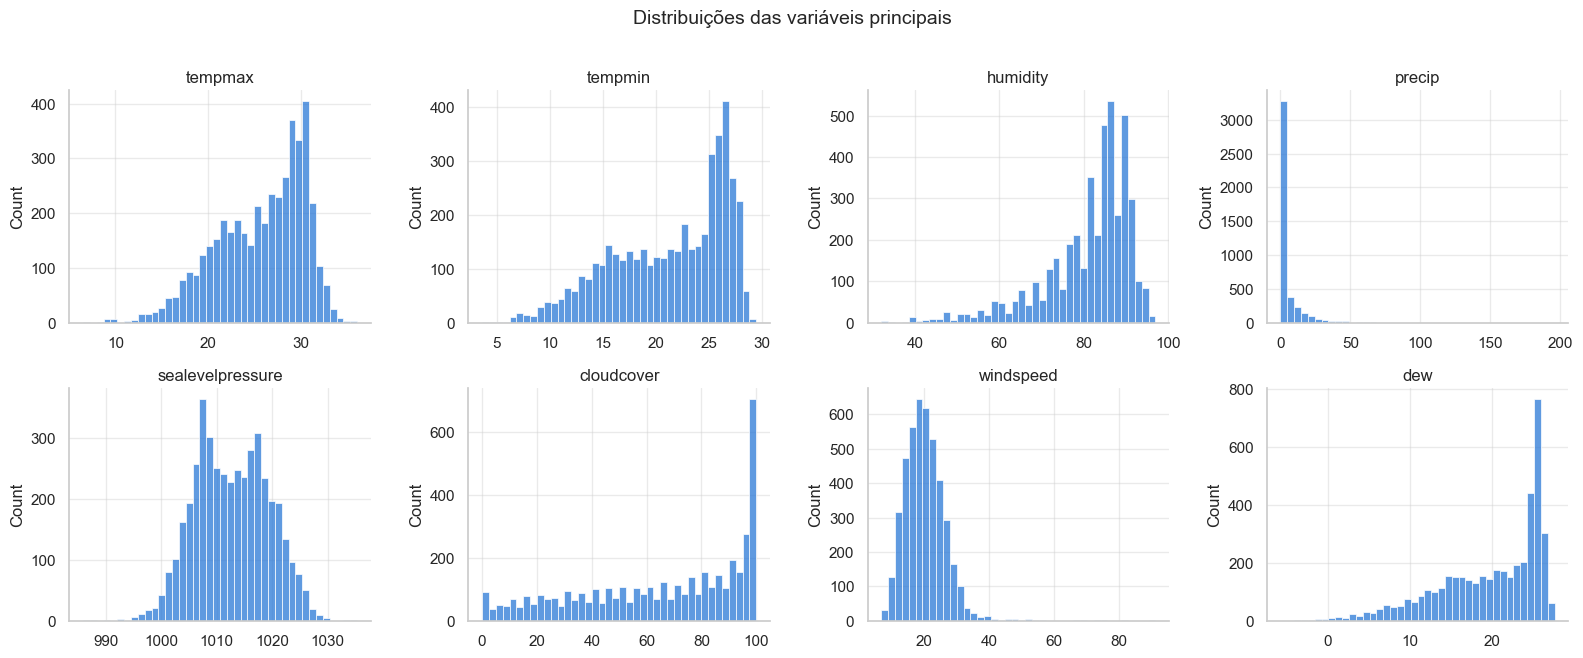

In [10]:
# ---------------------------------------------------------------
# 5.2 Distribuições das variáveis principais
# ---------------------------------------------------------------
key_vars = [c for c in ["tempmax", "tempmin", "humidity", "precip", "sealevelpressure", "cloudcover", "windspeed", "dew"] if c in df]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, col in zip(axes.ravel(), key_vars):
    sns.histplot(df[col], bins=40, ax=ax, color=C_BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Distribuições das variáveis principais", fontsize=14, y=1.01)
plt.tight_layout(); save_fig("eda_distributions"); plt.show()

**O que observar:** as temperaturas são **bimodais/assimétricas à esquerda** (verão longo e quente ~28–32 °C, inverno curto e ameno);
a **precipitação** é muito assimétrica (muitos dias com ~0 mm e poucos com > 50 mm); a **umidade** é alta quase sempre (clima subtropical úmido);
a **pressão** é mais alta no inverno (monção de nordeste/anticiclone siberiano) e mais baixa no verão.

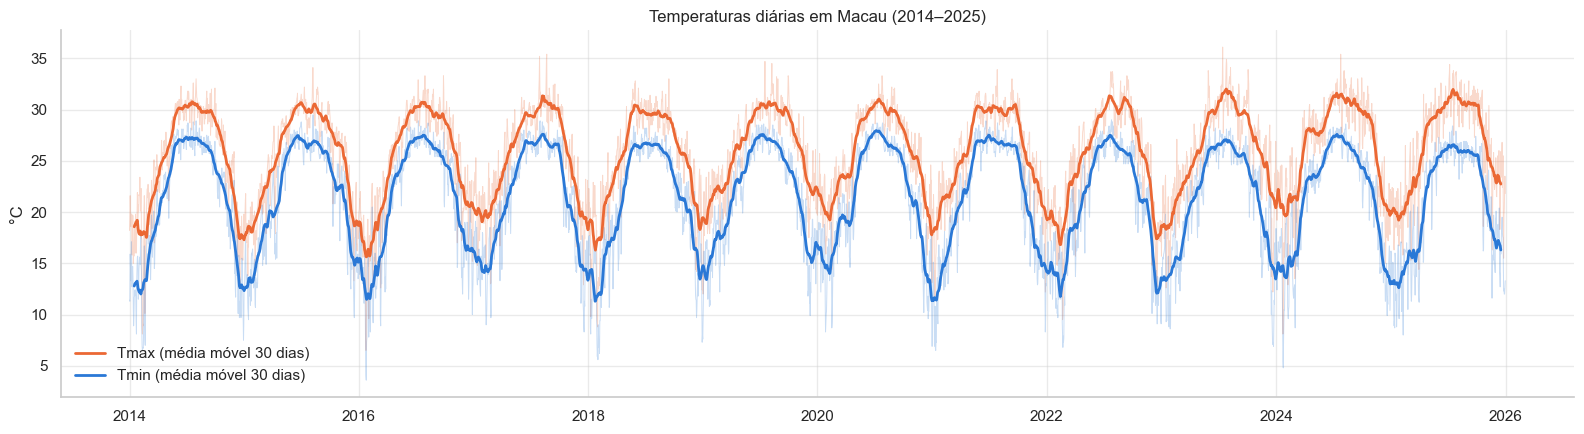

In [11]:
# ---------------------------------------------------------------
# 5.3 Série temporal das temperaturas (tendência e sazonalidade)
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(df.index, df["tempmax"], color=C_ORANGE, alpha=0.25, lw=0.7)
ax.plot(df.index, df["tempmin"], color=C_BLUE, alpha=0.25, lw=0.7)
ax.plot(df.index, df["tempmax"].rolling(30, center=True).mean(), color=C_ORANGE, lw=2, label="Tmax (média móvel 30 dias)")
ax.plot(df.index, df["tempmin"].rolling(30, center=True).mean(), color=C_BLUE, lw=2, label="Tmin (média móvel 30 dias)")
ax.set_ylabel("°C"); ax.set_title(f"Temperaturas diárias em {LOCATION_NAME} ({START_DATE[:4]}–{END_DATE[:4]})")
ax.legend(loc="lower left", frameon=False)
plt.tight_layout(); save_fig("eda_timeseries_temp"); plt.show()

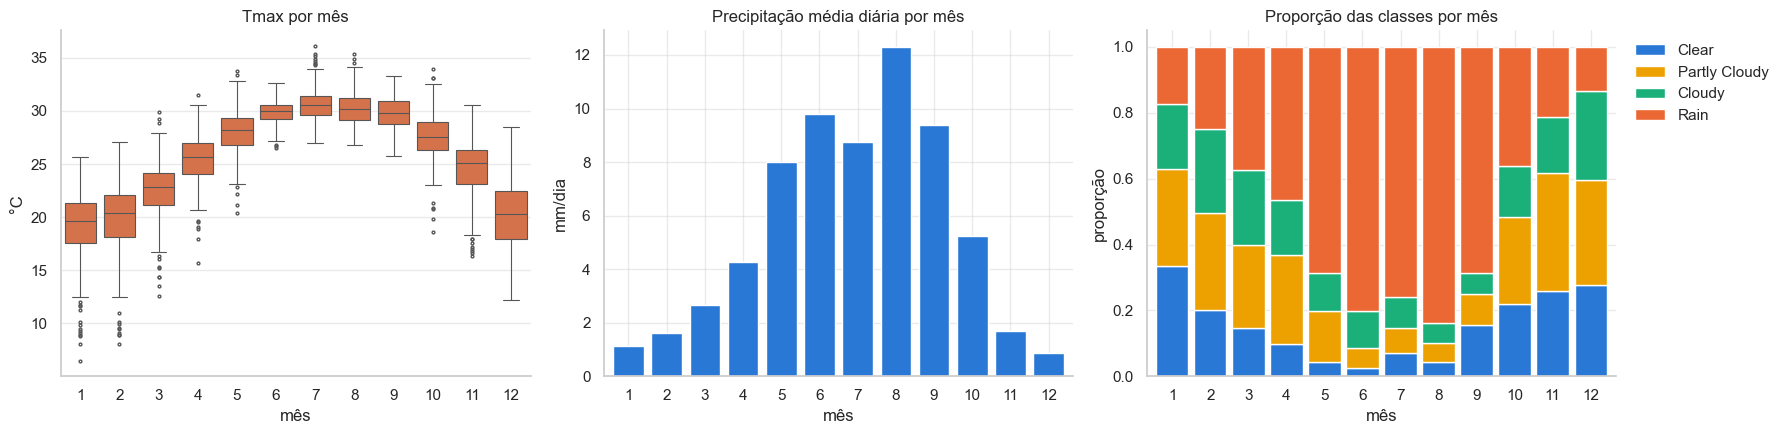

In [12]:
# ---------------------------------------------------------------
# 5.4 Sazonalidade mensal: temperatura, chuva e classes
# ---------------------------------------------------------------
tmp = df.assign(month=df.index.month)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# (a) Boxplot mensal de Tmax
sns.boxplot(data=tmp, x="month", y="tempmax", ax=axes[0], color=C_ORANGE, fliersize=2, linewidth=0.8)
axes[0].set_title("Tmax por mês"); axes[0].set_ylabel("°C"); axes[0].set_xlabel("mês")

# (b) Precipitação média por mês
tmp.groupby("month")["precip"].mean().plot.bar(ax=axes[1], color=C_BLUE, width=0.8, edgecolor="white")
axes[1].set_title("Precipitação média diária por mês"); axes[1].set_ylabel("mm/dia"); axes[1].set_xlabel("mês")
axes[1].tick_params(axis="x", rotation=0)

# (c) Proporção de cada classe por mês (barras empilhadas)
prop = pd.crosstab(tmp["month"], tmp["cond_class"], normalize="index")[CLASSES]
prop.plot.bar(stacked=True, ax=axes[2], color=[CLASS_COLORS[c] for c in CLASSES], width=0.85, edgecolor="white", linewidth=1)
axes[2].set_title("Proporção das classes por mês"); axes[2].set_ylabel("proporção"); axes[2].set_xlabel("mês")
axes[2].tick_params(axis="x", rotation=0)
axes[2].legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout(); save_fig("eda_seasonality"); plt.show()

**Insights de sazonalidade (fundamentais para a modelagem):**
* A temperatura segue um **ciclo anual** muito forte (pico em jul–ago, mínimo em jan–fev) → criaremos features **seno/cosseno do dia do ano**.
* A **chuva domina de maio a setembro** (monção de verão + tufões) e é rara no inverno → o mês ajuda muito a prever a classe.
* No inverno predominam *Clear* e *Partly Cloudy*; *Cloudy* (encoberto sem chuva) é mais comum de dez a mar, típico das massas de ar frias e úmidas do inverno/início da primavera.

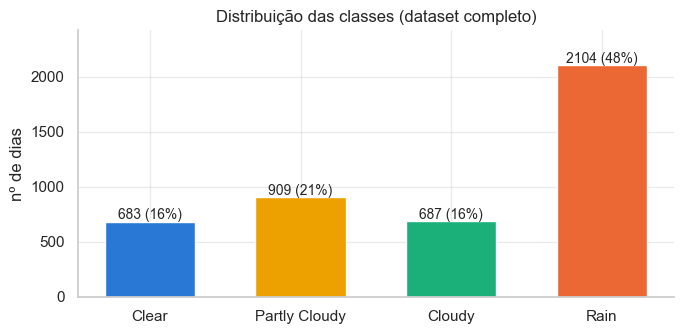

In [13]:
# ---------------------------------------------------------------
# 5.5 Desbalanceamento de classes
# ---------------------------------------------------------------
counts = df["cond_class"].value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(CLASSES, counts.values, color=[CLASS_COLORS[c] for c in CLASSES], width=0.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 20, f"{v} ({v / counts.sum():.0%})", ha="center", fontsize=10)
ax.set_title("Distribuição das classes (dataset completo)"); ax.set_ylabel("nº de dias")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout(); save_fig("eda_class_balance"); plt.show()

**Desbalanceamento:** *Rain* é a classe majoritária (~metade dos dias) e as outras três dividem o resto.
Consequências práticas:
* **Acurácia sozinha engana** – um modelo que sempre diz "Rain" já acerta ~48 %. Por isso a métrica principal da classificação será o **F1‑macro** (média do F1 de cada classe, que dá o mesmo peso às classes minoritárias).
* Usaremos `class_weight="balanced"` nos modelos, para penalizar mais os erros nas classes raras.

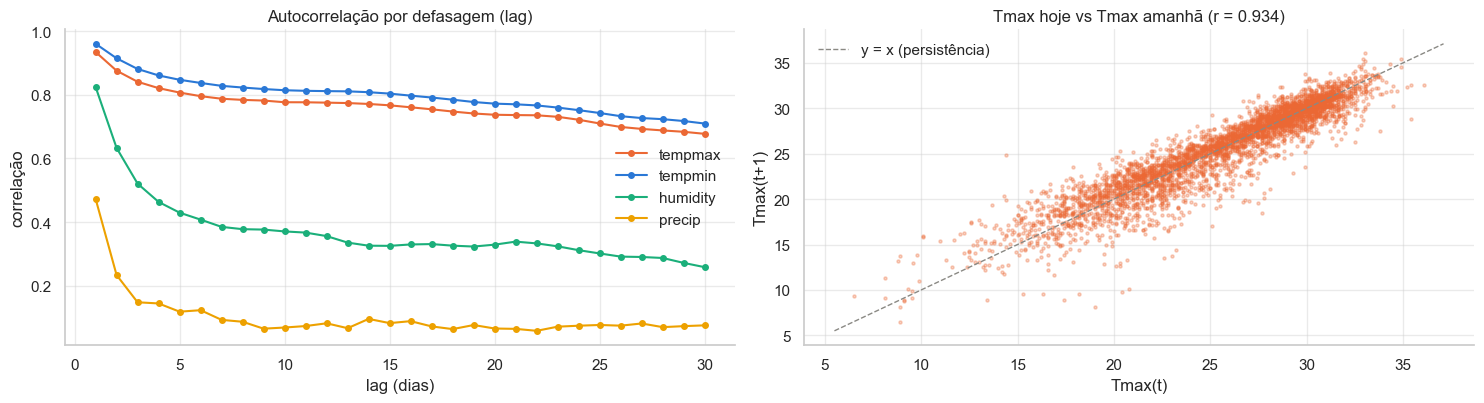

In [14]:
# ---------------------------------------------------------------
# 5.6 Autocorrelação: quão parecido é hoje com ontem, anteontem...?
# ---------------------------------------------------------------
lags = range(1, 31)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for col, color in [("tempmax", C_ORANGE), ("tempmin", C_BLUE), ("humidity", C_AQUA), ("precip", C_YELLOW)]:
    axes[0].plot(list(lags), [df[col].autocorr(l) for l in lags], marker="o", ms=4, color=color, label=col)
axes[0].set_title("Autocorrelação por defasagem (lag)"); axes[0].set_xlabel("lag (dias)"); axes[0].set_ylabel("correlação")
axes[0].legend(frameon=False)

# Dispersão: Tmax de hoje vs Tmax de amanhã (a lógica do baseline de persistência)
axes[1].scatter(df["tempmax"].iloc[:-1], df["tempmax"].shift(-1).iloc[:-1], s=5, alpha=0.3, color=C_ORANGE)
lims = [df["tempmax"].min() - 1, df["tempmax"].max() + 1]
axes[1].plot(lims, lims, color=C_GRAY, ls="--", lw=1, label="y = x (persistência)")
r = df["tempmax"].autocorr(1)
axes[1].set_title(f"Tmax hoje vs Tmax amanhã (r = {r:.3f})"); axes[1].set_xlabel("Tmax(t)"); axes[1].set_ylabel("Tmax(t+1)")
axes[1].legend(frameon=False)
plt.tight_layout(); save_fig("eda_autocorrelation"); plt.show()

**Por que isso importa:** a temperatura tem autocorrelação **altíssima** no lag 1 (r ≈ 0,93) e decai devagar →
"amanhã ≈ hoje" já é uma previsão forte (o baseline de persistência será **difícil de bater**). Os **lags** (t‑1, t‑2) e as **médias móveis**
capturam essa *memória* da série. A precipitação tem autocorrelação bem menor – a chuva é muito mais "aleatória" de um dia para o outro,
então a classificação é intrinsecamente mais difícil que a regressão.

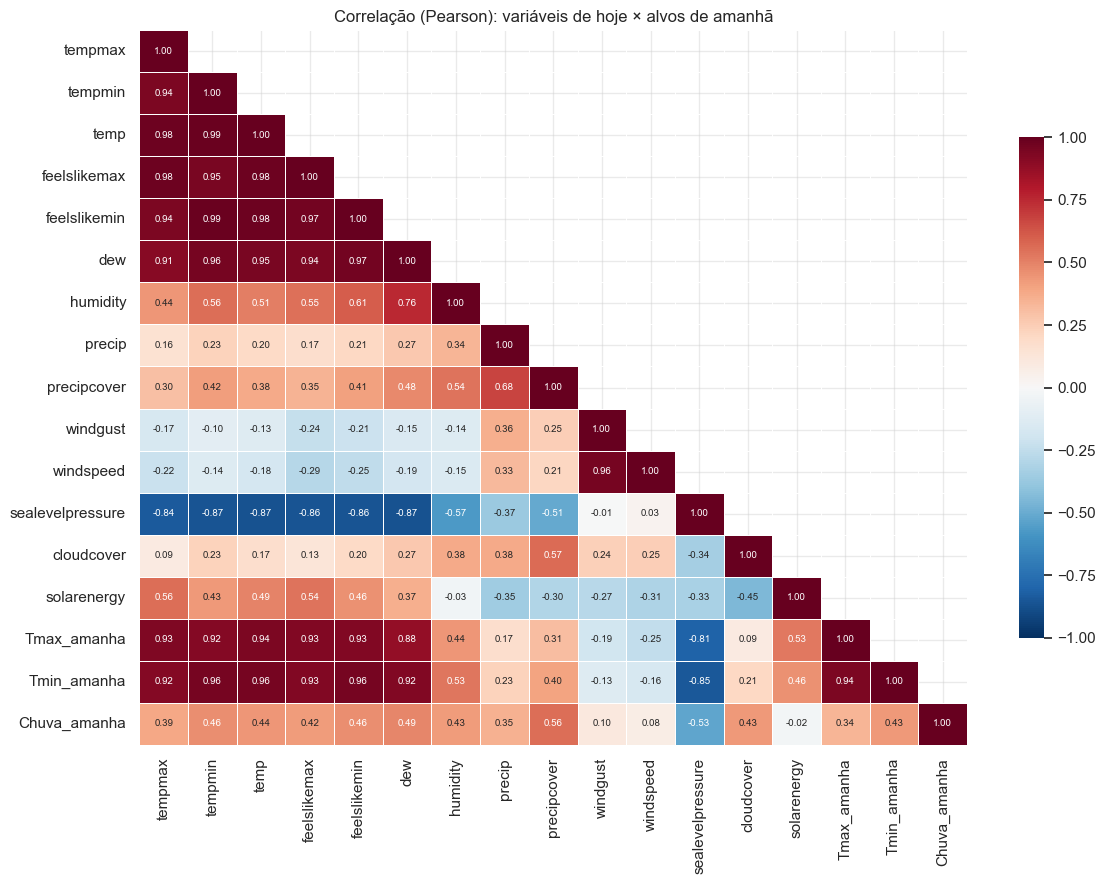

Correlação com os alvos de amanhã (ordenada):


,Tmax_amanha,Tmin_amanha,Chuva_amanha
precipcover,0.31,0.40,0.56
dew,0.88,0.92,0.49
tempmin,0.92,0.96,0.46
feelslikemin,0.93,0.96,0.46
temp,0.94,0.96,0.44
cloudcover,0.09,0.21,0.43
humidity,0.44,0.53,0.43
feelslikemax,0.93,0.93,0.42
tempmax,0.93,0.92,0.39
precip,0.17,0.23,0.35


In [15]:
# ---------------------------------------------------------------
# 5.7 Correlação entre variáveis de HOJE e os alvos de AMANHÃ
# ---------------------------------------------------------------
corr_df = df[[c for c in NUM_COLS if c != "winddir"]].copy()
corr_df["Tmax_amanha"] = df["tempmax"].shift(-1)
corr_df["Tmin_amanha"] = df["tempmin"].shift(-1)
corr_df["Chuva_amanha"] = (df["cond_class"].shift(-1) == "Rain").astype(float)
corr = corr_df.dropna().corr()

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.5, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlação (Pearson): variáveis de hoje × alvos de amanhã")
plt.tight_layout(); save_fig("eda_correlation"); plt.show()

print("Correlação com os alvos de amanhã (ordenada):")
corr[["Tmax_amanha", "Tmin_amanha", "Chuva_amanha"]].drop(["Tmax_amanha", "Tmin_amanha", "Chuva_amanha"]) \
    .sort_values("Chuva_amanha", ascending=False).round(2)

**Leitura do mapa de correlação:**
* Os alvos de temperatura estão fortemente correlacionados com **todas as temperaturas de hoje** e com o **ponto de orvalho** (ar úmido = noites quentes),
  e **negativamente com a pressão** (pressão alta = massa de ar fria do inverno).
* Há **multicolinearidade** forte entre `temp`, `tempmax`, `feelslike*` e `dew` → para o modelo linear isso pede **regularização (Ridge)**; para as árvores não é problema.
* A **chuva de amanhã** se relaciona com umidade, ponto de orvalho, cobertura de nuvens e `precipcover` de hoje, e negativamente com a pressão e a energia solar.

Média por classe de AMANHÃ (variáveis de hoje):


,humidity,sealevelpressure,dpressao
classe_amanha,,,
Clear,72.96,1017.13,-0.04
Partly Cloudy,77.77,1015.87,-0.02
Cloudy,78.43,1015.08,0.19
Rain,85.53,1009.04,-0.04


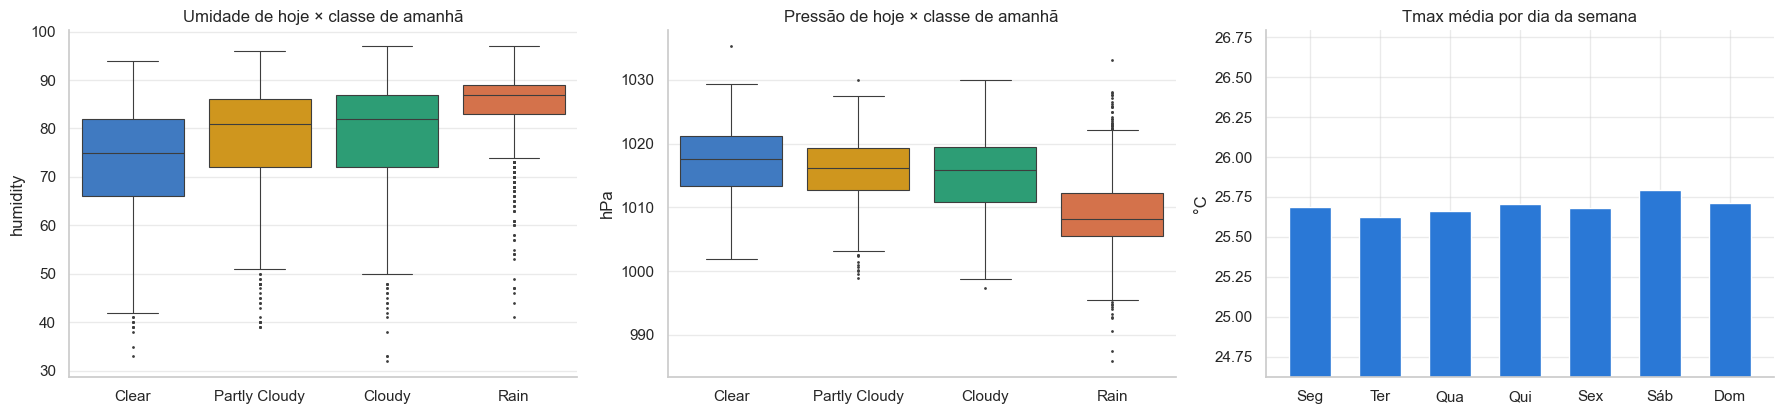

In [16]:
# ---------------------------------------------------------------
# 5.8 Relação features x classe de amanhã + checagem do "dia da semana"
# ---------------------------------------------------------------
tmp = df.copy()
tmp["classe_amanha"] = tmp["cond_class"].shift(-1)
tmp["dpressao"] = tmp["sealevelpressure"].diff()            # variação da pressão de ontem para hoje
tmp = tmp.dropna()
print("Média por classe de AMANHÃ (variáveis de hoje):")
display(tmp.groupby("classe_amanha")[["humidity", "sealevelpressure", "dpressao"]].mean().loc[CLASSES].round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
pal = [CLASS_COLORS[c] for c in CLASSES]
sns.boxplot(data=tmp, x="classe_amanha", y="humidity", order=CLASSES, palette=pal, ax=axes[0], fliersize=1, linewidth=0.8)
axes[0].set_title("Umidade de hoje × classe de amanhã"); axes[0].set_xlabel("")
sns.boxplot(data=tmp, x="classe_amanha", y="sealevelpressure", order=CLASSES, palette=pal, ax=axes[1], fliersize=1, linewidth=0.8)
axes[1].set_title("Pressão de hoje × classe de amanhã"); axes[1].set_xlabel(""); axes[1].set_ylabel("hPa")

# Dia da semana: o tempo NÃO deveria depender do calendário humano
dow = df.groupby(df.index.dayofweek)["tempmax"].mean()
axes[2].bar(["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"], dow.values, color=C_BLUE, width=0.6)
axes[2].set_ylim(dow.min() - 1, dow.max() + 1)
axes[2].set_title("Tmax média por dia da semana"); axes[2].set_ylabel("°C")
plt.tight_layout(); save_fig("eda_relationships"); plt.show()

**Conclusões:**
* Dias seguidos de **Rain** têm umidade mais alta hoje; dias seguidos de **Clear** têm a umidade mais baixa → umidade é preditiva.
* **Pressão alta** (anticiclone, ar seco) antecede dias *Clear*; **pressão baixa** (~1009 hPa, cavados e sistemas tropicais) antecede *Rain*.
  A **variação** diária da pressão, na média do ano todo, quase não difere entre as classes (sinal fraco), mas a mantemos como feature
  por ser fisicamente motivada (frentes frias e sistemas tropicais mudam a pressão) – o modelo decide se ela é útil.
* O **dia da semana não tem efeito** (variação < 0,2 °C entre os dias, puro ruído) – faz sentido físico. A especificação sugere testar features de calendário,
  mas, com base nesta evidência, **não usaremos o dia da semana** como feature (evita ruído e sobreajuste). Da mesma forma, "hora do dia" não se
  aplica, pois os dados são **diários**.

---
## 6. Engenharia de features

**Princípio de ouro (sem vazamento de dados / *data leakage*):** para prever o dia **t+1**, só podemos usar informação disponível
até o **fim do dia t**. Todas as features abaixo usam apenas os dias t, t‑1, t‑2, …; os alvos são deslocados para o futuro com `shift(-1)`.

| Grupo | Features | Por quê |
|---|---|---|
| **Hoje (t)** | as 14 variáveis medidas no dia | o estado atual da atmosfera é o melhor preditor do estado de amanhã |
| **Lags** | valores de t‑1 e t‑2 das variáveis principais | capturam a **dinâmica** (está esquentando? a umidade está subindo?) |
| **Diferenças** | Tmax(t) − Tmax(t‑1), pressão(t) − pressão(t‑1), pressão(t) − pressão(t‑3) | tendência de curto prazo; queda de pressão = chegada de sistemas de chuva |
| **Médias móveis** | médias de 3, 7 e 14 dias (janela termina em t); desvio‑padrão de 7 dias | suavizam o ruído diário e representam o "regime" recente |
| **Físicas / domínio** | amplitude térmica (Tmax−Tmin), depressão do ponto de orvalho (T−Td), anomalia (T − média 30 dias) | Td próximo de T = ar saturado = chuva/nuvens; anomalia indica massa de ar fora do normal |
| **Sazonalidade cíclica** | seno/cosseno do dia do ano e do mês | codifica que 31/dez e 1/jan são vizinhos (o mês "12" não fica longe do "1") |
| **Vento** | seno/cosseno da direção | direção é circular (359° ≈ 1°); vento de N/NE no inverno traz ar frio e seco |
| **Categórica** | classe de hoje em *one‑hot* (4 colunas 0/1) | persistência do tipo de tempo; one‑hot evita impor uma ordem falsa entre classes |

**Escalonamento:** é feito **dentro de um `Pipeline`** com `StandardScaler` apenas para os modelos lineares (Ridge e Regressão Logística),
que são sensíveis à escala. O scaler é ajustado **somente no treino** em cada etapa → sem vazamento. Árvores não precisam de escala.

In [17]:
# ---------------------------------------------------------------
# 6.1 Função de engenharia de features
# ---------------------------------------------------------------
LAG_VARS     = ["tempmax", "tempmin", "temp", "dew", "humidity", "precip",
                "sealevelpressure", "cloudcover", "windspeed", "solarenergy"]
ROLL_VARS    = ["tempmax", "tempmin", "temp", "humidity", "precip", "sealevelpressure", "cloudcover"]
ROLL_WINDOWS = [3, 7, 14]


def build_features(data):
    '''
    Responsabilidade: transformar o DataFrame limpo numa MATRIZ DE FEATURES + ALVOS.
    Entrada : DataFrame diário limpo (índice = data) com NUMERIC_COLS e 'cond_class'.
    Saída   : (feat, feature_cols) onde feat contém features + colunas-alvo:
              target_tmax, target_tmin, target_cond (valores do dia t+1) e target_date.
    Garantia anti-vazamento: features usam somente t, t-1, t-2...; alvos usam shift(-1).
    '''
    d = data.copy()
    f = pd.DataFrame(index=d.index)

    # (1) Variáveis do próprio dia t (exceto winddir, que será codificada abaixo)
    for c in NUM_COLS:
        if c != "winddir":
            f[c] = d[c]

    # (2) Lags t-1 e t-2
    for c in [v for v in LAG_VARS if v in d]:
        for k in (1, 2):
            f[f"{c}_lag{k}"] = d[c].shift(k)

    # (3) Diferenças (tendências de curto prazo)
    f["tempmax_diff1"]  = d["tempmax"].diff(1)
    f["tempmin_diff1"]  = d["tempmin"].diff(1)
    f["pressure_diff1"] = d["sealevelpressure"].diff(1)
    f["pressure_diff3"] = d["sealevelpressure"].diff(3)
    f["humidity_diff1"] = d["humidity"].diff(1)

    # (4) Médias móveis (janela inclui o dia t e termina nele -> só passado/presente)
    for c in [v for v in ROLL_VARS if v in d]:
        for w in ROLL_WINDOWS:
            f[f"{c}_roll{w}"] = d[c].rolling(w).mean()
    f["temp_std7"]     = d["temp"].rolling(7).std()
    f["pressure_std7"] = d["sealevelpressure"].rolling(7).std()
    f["rain_days7"]    = (d["cond_class"] == "Rain").astype(int).rolling(7).sum()   # dias de chuva na última semana

    # (5) Features físicas / de domínio
    f["temp_range"]     = d["tempmax"] - d["tempmin"]          # amplitude térmica (céu limpo -> amplitude alta)
    f["dewpoint_dep"]   = d["temp"] - d["dew"]                 # perto de 0 => ar saturado
    f["temp_anomaly30"] = d["temp"] - d["temp"].rolling(30).mean()

    # (6) Sazonalidade cíclica
    doy = d.index.dayofyear
    f["doy_sin"]   = np.sin(2 * np.pi * doy / 365.25)
    f["doy_cos"]   = np.cos(2 * np.pi * doy / 365.25)
    f["month_sin"] = np.sin(2 * np.pi * d.index.month / 12)
    f["month_cos"] = np.cos(2 * np.pi * d.index.month / 12)

    # (7) Direção do vento circular -> seno/cosseno
    if "winddir" in d:
        f["winddir_sin"] = np.sin(np.deg2rad(d["winddir"]))
        f["winddir_cos"] = np.cos(np.deg2rad(d["winddir"]))

    # (8) Classe de hoje em one-hot
    for c in CLASSES:
        f[f"today_{c.replace(' ', '_')}"] = (d["cond_class"] == c).astype(int)

    feature_cols = list(f.columns)

    # (9) ALVOS: valores de AMANHÃ (t+1)
    f["target_tmax"] = d["tempmax"].shift(-1)
    f["target_tmin"] = d["tempmin"].shift(-1)
    f["target_cond"] = d["cond_class"].shift(-1)
    f["target_date"] = d.index + pd.Timedelta(days=1)

    # Remove as primeiras linhas (sem histórico suficiente p/ lags/rolling) e a última (sem alvo)
    f = f.dropna()
    return f, feature_cols


feat, FEATURES = build_features(df)
print(f"Matriz final: {feat.shape[0]} linhas | {len(FEATURES)} features")
feat.to_csv(PROCESSED_DIR / "macau_features_processed.csv")
feat[FEATURES[:6] + ["tempmax_lag1", "tempmax_roll7", "doy_sin", "target_tmax", "target_tmin", "target_cond"]].head()

Matriz final: 4353 linhas | 76 features


,tempmax,tempmin,temp,feelslikemax,feelslikemin,dew,tempmax_lag1,tempmax_roll7,doy_sin,target_tmax,target_tmin,target_cond
date,,,,,,,,,,,,
2014-01-30,20.1,12.2,16.6,21.6,12.2,14.2,20.7,20.028571,0.493468,21.7,14.4,Clear
2014-01-31,21.7,14.4,17.9,23.0,15.5,15.5,20.1,20.442857,0.508356,21.6,15.2,Partly Cloudy
2014-02-01,21.6,15.2,18.4,23.0,16.3,16.6,21.7,20.671429,0.523094,21.8,15.6,Partly Cloudy
2014-02-02,21.8,15.6,18.3,24.0,16.9,16.4,21.6,20.657143,0.537677,23.4,15.4,Clear
2014-02-03,23.4,15.4,19.2,26.0,15.5,15.5,21.8,21.271429,0.552101,21.2,14.9,Partly Cloudy


In [18]:
# ---------------------------------------------------------------
# 6.2 Teste de sanidade anti-vazamento (boa prática de QA)
# ---------------------------------------------------------------
# Se o alvo foi construído corretamente, target_tmax do dia t deve ser IGUAL ao tempmax do dia t+1
check = (feat["target_tmax"].iloc[:-1].values == df.loc[feat.index[1:], "tempmax"].values).mean()
print(f"target_tmax(t) == tempmax(t+1) em {check:.1%} das linhas")
# E nenhuma feature pode ser cópia do alvo (correlação 1.0 perfeita indicaria vazamento)
max_corr = feat[FEATURES].corrwith(feat["target_tmax"]).abs().max()
print(f"Maior |correlação| feature-alvo: {max_corr:.3f}  (< 1 -> nenhuma feature é o próprio alvo)")
assert check > 0.99 and max_corr < 0.999

target_tmax(t) == tempmax(t+1) em 100.0% das linhas
Maior |correlação| feature-alvo: 0.939  (< 1 -> nenhuma feature é o próprio alvo)


---
## 7. Divisão cronológica: treino / validação / teste

⚠️ Em séries temporais **nunca** usamos divisão aleatória (`train_test_split` com `shuffle`): o modelo veria o futuro durante o treino
(ex.: treinar com 15/jul e testar com 14/jul) e as métricas ficariam artificialmente otimistas.

Usamos blocos cronológicos definidos pela **data do alvo** (o dia previsto):

| Conjunto | Período do alvo | Uso |
|---|---|---|
| **Treino** | 2014 → 2021 (8 anos) | ajustar os modelos; tuning com validação cruzada temporal |
| **Validação** | 2022 → 2023 (2 anos) | comparar modelos e escolher o final |
| **Teste** | 2024 → 2025 (2 anos) | avaliação **única** e final (dados "nunca vistos") |

Dividir pela data do alvo garante que **nenhum rótulo** de um conjunto posterior entre no treino de um anterior.
Dois anos completos em validação e teste cobrem **todas as estações** (inclusive duas temporadas de tufões).

Treino    :  2892 linhas | alvos de 2014-01-31 a 2021-12-31
Validação :   730 linhas | alvos de 2022-01-01 a 2023-12-31
Teste     :   731 linhas | alvos de 2024-01-01 a 2025-12-31


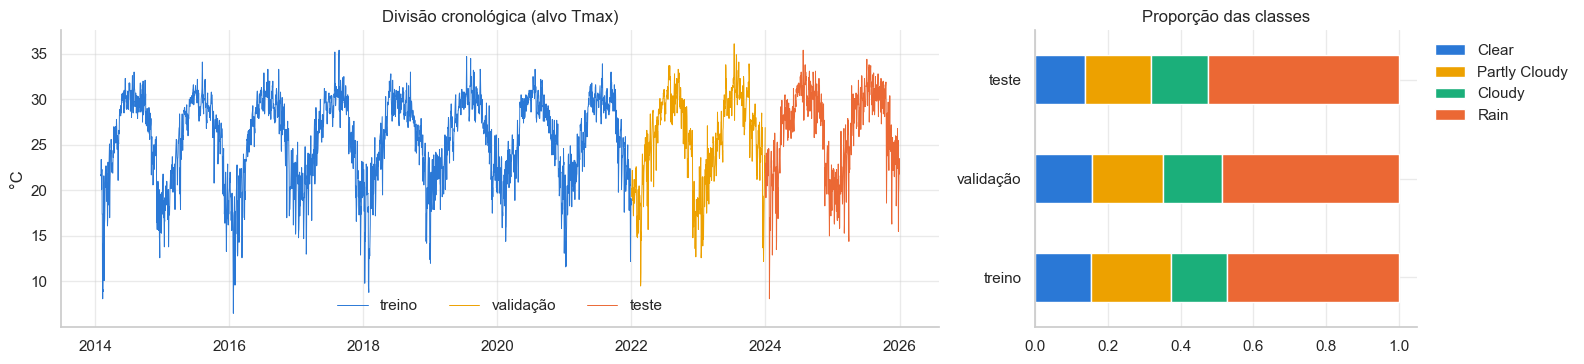

In [19]:
# ---------------------------------------------------------------
# 7.1 Divisão cronológica
# ---------------------------------------------------------------
def chronological_split(feat):
    '''
    Responsabilidade: separar a matriz em treino/validação/teste pela DATA DO ALVO.
    Retorna três DataFrames, sem embaralhar e preservando a ordem temporal.
    '''
    td = feat["target_date"]
    train = feat[td <= TRAIN_END]
    val   = feat[(td > TRAIN_END) & (td <= VAL_END)]
    test  = feat[td > VAL_END]
    return train, val, test


train, val, test = chronological_split(feat)
for name, part in [("Treino", train), ("Validação", val), ("Teste", test)]:
    print(f"{name:10s}: {len(part):5d} linhas | alvos de {part['target_date'].min().date()} a {part['target_date'].max().date()}")

# Atalhos para as matrizes X e os alvos y
X_train, X_val, X_test = train[FEATURES], val[FEATURES], test[FEATURES]

# Visualização da divisão + proporção de classes em cada parte (verifica se as distribuições são parecidas)
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [2.3, 1]})
for part, color, lab in [(train, C_BLUE, "treino"), (val, C_YELLOW, "validação"), (test, C_ORANGE, "teste")]:
    axes[0].plot(part["target_date"], part["target_tmax"], color=color, lw=0.7, label=lab)
axes[0].set_title("Divisão cronológica (alvo Tmax)"); axes[0].set_ylabel("°C"); axes[0].legend(frameon=False, ncol=3)
dist = pd.DataFrame({n: p["target_cond"].value_counts(normalize=True) for n, p in
                     [("treino", train), ("validação", val), ("teste", test)]}).loc[CLASSES].T
dist.plot.barh(stacked=True, ax=axes[1], color=[CLASS_COLORS[c] for c in CLASSES], edgecolor="white", linewidth=1)
axes[1].set_title("Proporção das classes"); axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout(); save_fig("split"); plt.show()

---
## 8. TAREFA 1 – Regressão: Tmax e Tmin de amanhã

### 8.1 Métricas escolhidas (e por quê)
| Métrica | O que mede | Por que usar |
|---|---|---|
| **MAE** (erro absoluto médio) | erro médio em °C | **métrica principal**: fácil de explicar ("erramos em média 0,9 °C") e robusta a outliers |
| **RMSE** | raiz do erro quadrático médio | penaliza mais os **erros grandes** (ex.: frentes frias não previstas) |
| **R²** | fração da variância explicada | comparação relativa (1 = perfeito, 0 = prever a média) |
| **r de Pearson** | correlação previsão × real | mede se acompanhamos as subidas/descidas |

### 8.2 Modelos
* **Baseline – Persistência:** "Tmax de amanhã = Tmax de hoje" (sugerido pela especificação). Simples, sem treino e – como vimos na autocorrelação – forte.
* **Referência extra – Climatologia:** média histórica (do treino) para aquele dia do ano. Mostra quanto se ganha olhando o estado atual além do calendário.
* **Ridge Regression** (linear com regularização L2): rápido, interpretável; a regularização lida com a multicolinearidade forte entre as temperaturas. Exige escala → `Pipeline(StandardScaler, Ridge)`.
* **Random Forest:** média de muitas árvores de decisão em amostras bootstrap; captura **não‑linearidades e interações** (ex.: o efeito da umidade depende da estação) sem precisar de escala; robusto a outliers.
* **HistGradientBoosting** (gradient boosting do scikit‑learn, equivalente ao LightGBM): árvores construídas em sequência, cada uma corrigindo os erros da anterior; costuma ser o estado da arte em dados tabulares.

Treinamos **um modelo por alvo** (Tmax e Tmin), pois os fatores físicos diferem (Tmax depende do sol/nuvens; Tmin da umidade/nuvens à noite).

In [20]:
# ---------------------------------------------------------------
# 8.3 Funções auxiliares de regressão
# ---------------------------------------------------------------
REG_TARGETS = {"target_tmax": ("tempmax", "Tmax"), "target_tmin": ("tempmin", "Tmin")}


def regression_metrics(y_true, y_pred):
    '''Responsabilidade: calcular MAE, RMSE, R² e correlação de Pearson. Retorna um dict.'''
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred),
            "Pearson_r": pearsonr(y_true, y_pred)[0]}


def make_regressors():
    '''
    Responsabilidade: devolver NOVAS instâncias (não treinadas) dos 3 modelos de regressão,
    com hiperparâmetros iniciais razoáveis (documentados aqui mesmo).
    '''
    return {
        "Ridge": Pipeline([("scaler", StandardScaler()),
                           ("model", Ridge(alpha=1.0))]),                    # alpha = força da regularização
        "RandomForest": RandomForestRegressor(n_estimators=300,              # nº de árvores
                                              min_samples_leaf=2,            # mín. de amostras por folha (suaviza)
                                              max_features=0.5,              # fração de features por divisão
                                              n_jobs=-1, random_state=SEED),
        "HistGradBoost": HistGradientBoostingRegressor(learning_rate=0.05,   # passo de aprendizado
                                                       max_iter=400,         # nº de árvores (iterações)
                                                       max_leaf_nodes=31,    # complexidade de cada árvore
                                                       min_samples_leaf=20,
                                                       random_state=SEED),
    }


def climatology_predict(train_df, target_df, var):
    '''
    Responsabilidade: baseline de climatologia -> média do TREINO por dia do ano do alvo
    (suavizada com média móvel circular de 15 dias para reduzir ruído).
    '''
    doy_train = train_df["target_date"].dt.dayofyear
    clim = train_df.groupby(doy_train)[var].mean().reindex(range(1, 367)).interpolate()
    clim = pd.concat([clim.iloc[-7:], clim, clim.iloc[:7]]).rolling(15, center=True).mean().iloc[7:-7]
    return clim.loc[target_df["target_date"].dt.dayofyear].values

In [21]:
# ---------------------------------------------------------------
# 8.4 Baselines + 3 modelos: treino no TREINO, avaliação na VALIDAÇÃO
# ---------------------------------------------------------------
reg_val_rows = []        # linhas da tabela de resultados
reg_fitted   = {}        # modelos treinados: reg_fitted[(alvo, nome)]
reg_val_pred = {}        # previsões na validação: reg_val_pred[(alvo, nome)]

for target, (today_col, label) in REG_TARGETS.items():
    y_tr, y_va = train[target], val[target]

    # Baseline de persistência: amanhã = hoje
    reg_val_pred[(target, "Persistence")] = val[today_col].values
    # Referência de climatologia
    reg_val_pred[(target, "Climatology")] = climatology_predict(train, val, target)

    # Modelos de ML
    for name, model in make_regressors().items():
        t0 = time.time()
        model.fit(X_train, y_tr)
        reg_fitted[(target, name)] = model
        reg_val_pred[(target, name)] = model.predict(X_val)
        print(f"{label} | {name:13s} treinado em {time.time() - t0:5.1f}s")

    for name in ["Persistence", "Climatology", "Ridge", "RandomForest", "HistGradBoost"]:
        reg_val_rows.append({"alvo": label, "modelo": name, **regression_metrics(y_va, reg_val_pred[(target, name)])})

reg_val_table = pd.DataFrame(reg_val_rows).set_index(["alvo", "modelo"]).round(3)
reg_val_table

Tmax | Ridge         treinado em   0.0s


Tmax | RandomForest  treinado em   1.0s


Tmax | HistGradBoost treinado em   1.9s
Tmin | Ridge         treinado em   0.0s


Tmin | RandomForest  treinado em   1.0s


Tmin | HistGradBoost treinado em   1.6s


MAE   RMSE     R2  Pearson_r
alvo modelo                                       
Tmax Persistence    1.244  1.716  0.880      0.940
     Climatology    1.826  2.399  0.765      0.875
     Ridge          1.033  1.348  0.926      0.963
     RandomForest   1.058  1.401  0.920      0.961
     HistGradBoost  1.054  1.377  0.922      0.962
Tmin Persistence    1.101  1.614  0.912      0.956
     Climatology    1.756  2.376  0.809      0.902
     Ridge          1.009  1.396  0.934      0.967
     RandomForest   1.000  1.380  0.935      0.967
     HistGradBoost  0.993  1.375  0.936      0.968

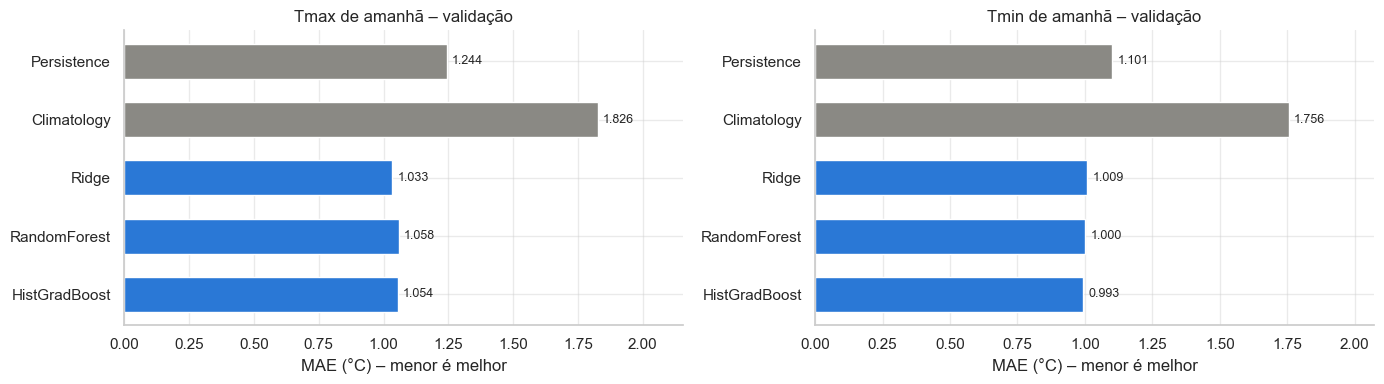

Tmax: melhor modelo na validação = Ridge (MAE 1.033) -> 17.0% melhor que a persistência (MAE 1.244)
Tmin: melhor modelo na validação = HistGradBoost (MAE 0.993) -> 9.8% melhor que a persistência (MAE 1.101)


In [22]:
# ---------------------------------------------------------------
# 8.5 Comparação visual (MAE na validação)
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
order = ["Persistence", "Climatology", "Ridge", "RandomForest", "HistGradBoost"]
for ax, label in zip(axes, ["Tmax", "Tmin"]):
    vals = reg_val_table.loc[label].loc[order, "MAE"]
    colors = [C_GRAY, C_GRAY, C_BLUE, C_BLUE, C_BLUE]
    bars = ax.barh(order, vals, color=colors, height=0.6)
    for b, v in zip(bars, vals):
        ax.text(v + 0.02, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center", fontsize=9)
    ax.invert_yaxis(); ax.set_xlabel("MAE (°C) – menor é melhor"); ax.set_title(f"{label} de amanhã – validação")
    ax.set_xlim(0, vals.max() * 1.18)
plt.tight_layout(); save_fig("reg_val_comparison"); plt.show()

# Melhoria relativa sobre a persistência
for label in ["Tmax", "Tmin"]:
    t = reg_val_table.loc[label]
    best = t.drop(["Persistence", "Climatology"])["MAE"].idxmin()
    gain = 1 - t.loc[best, "MAE"] / t.loc["Persistence", "MAE"]
    print(f"{label}: melhor modelo na validação = {best} (MAE {t.loc[best, 'MAE']:.3f}) "
          f"-> {gain:.1%} melhor que a persistência (MAE {t.loc['Persistence', 'MAE']:.3f})")

**Interpretação (validação).**
* Os três modelos de ML **vencem a persistência** nos dois alvos: em Tmax o erro cai de ~1,24 °C para ~1,03 °C (−17 %); em Tmin de ~1,10 °C para ~0,99 °C (−10 %).
* A **climatologia** é bem pior (~1,8 °C): saber só a data não basta; o estado atual da atmosfera é o que mais informa.
* As diferenças **entre** os modelos de ML são pequenas (centésimos de grau). O **Ridge** (linear) é o melhor em Tmax e o **HistGradBoost** em Tmin –
  sinal de que a relação é majoritariamente linear e que as features fazem o trabalho pesado.

> 📌 *Os números citados nos textos de interpretação referem‑se à execução de referência (dados Open‑Meteo, semente 42). Se você trocar a fonte para o Visual Crossing, os valores mudam um pouco, mas a metodologia é a mesma; as tabelas e o resumo da Seção 10 são sempre gerados automaticamente.*

### 8.6 Ajuste de hiperparâmetros (tuning)

**Método:** `RandomizedSearchCV` com **`TimeSeriesSplit`** (5 dobras, `gap=1`) **somente nos dados de treino**.

* **Por que TimeSeriesSplit?** Cada dobra treina no passado e valida no período imediatamente seguinte (janela expansível),
  respeitando a ordem temporal – a versão "temporal" da validação cruzada. `gap=1` descarta 1 dia entre treino e validação de cada dobra,
  evitando que o alvo do último dia de treino seja a feature do primeiro dia de validação.
* **Por que busca aleatória (randomized) e não grid?** Com o mesmo orçamento (30 combinações), a busca aleatória explora melhor espaços
  com muitos hiperparâmetros (Bergstra & Bengio, 2012), especialmente quando só alguns deles importam muito.
* **Métrica otimizada:** MAE (negativo, pois o scikit‑learn maximiza).
* **Qual modelo ajustar?** O **melhor candidato de ML na validação** (escolhido automaticamente pelo código, como manda a especificação).
  Depois conferimos na validação se o tuning realmente ajudou.

In [23]:
# ---------------------------------------------------------------
# 8.6 Tuning do melhor modelo de regressão (por alvo)
# ---------------------------------------------------------------
REG_PARAM_SPACES = {
    "Ridge": {"model__alpha": loguniform(1e-3, 1e3)},
    "RandomForest": {"n_estimators": randint(200, 600),
                     "max_depth": [None, 8, 12, 16, 24],
                     "min_samples_leaf": randint(1, 10),
                     "max_features": [0.2, 0.3, 0.5, 0.7, "sqrt"]},
    "HistGradBoost": {"learning_rate": loguniform(0.01, 0.2),
                      "max_iter": randint(150, 800),
                      "max_leaf_nodes": randint(8, 64),
                      "min_samples_leaf": randint(10, 80),
                      "max_depth": [None, 3, 5, 8],
                      "l2_regularization": loguniform(1e-3, 10)},
}
tscv = TimeSeriesSplit(n_splits=5, gap=1)


def tune_model(base_model, param_space, X, y, scoring, n_iter=30):
    '''
    Responsabilidade: executar a busca aleatória de hiperparâmetros com validação cruzada
    temporal e devolver o objeto RandomizedSearchCV já ajustado (best_estimator_ treinado em X).
    '''
    search = RandomizedSearchCV(clone(base_model), param_space, n_iter=n_iter, scoring=scoring,
                                cv=tscv, n_jobs=-1, random_state=SEED, refit=True)
    search.fit(X, y)
    return search


reg_best_name, reg_tuned = {}, {}
for target, (_, label) in REG_TARGETS.items():
    cand = reg_val_table.loc[label].drop(["Persistence", "Climatology"])
    best = cand["MAE"].idxmin()
    reg_best_name[target] = best
    t0 = time.time()
    search = tune_model(make_regressors()[best], REG_PARAM_SPACES[best], X_train, train[target],
                        scoring="neg_mean_absolute_error")
    reg_tuned[target] = search.best_estimator_
    pred = search.best_estimator_.predict(X_val)
    reg_val_pred[(target, best + "_tuned")] = pred
    m = regression_metrics(val[target], pred)
    print(f"\n{label}: modelo ajustado = {best}  ({time.time() - t0:.0f}s)")
    print(f"  Melhores hiperparâmetros: { {k: (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()} }")
    print(f"  MAE CV (treino, TimeSeriesSplit): {-search.best_score_:.3f}")
    print(f"  MAE validação: antes {cand.loc[best, 'MAE']:.3f} -> depois {m['MAE']:.3f}")


Tmax: modelo ajustado = Ridge  (2s)
  Melhores hiperparâmetros: {'model__alpha': np.float64(51.411)}
  MAE CV (treino, TimeSeriesSplit): 0.992
  MAE validação: antes 1.033 -> depois 1.046



Tmin: modelo ajustado = HistGradBoost  (16s)
  Melhores hiperparâmetros: {'l2_regularization': np.float64(0.4014), 'learning_rate': np.float64(0.0118), 'max_depth': 8, 'max_iter': 641, 'max_leaf_nodes': 37, 'min_samples_leaf': 47}
  MAE CV (treino, TimeSeriesSplit): 0.926
  MAE validação: antes 0.993 -> depois 0.989


**Interpretação do tuning.** O tuning escolheu a melhor configuração pela validação cruzada temporal no treino, mas na validação (2022–2023) o ganho foi **nulo ou marginal**
(Tmin: 0,993 → 0,989; Tmax/Ridge: 1,033 → 1,046, ligeiramente pior). Isso é comum e é uma lição importante:
* os modelos já partiam de hiperparâmetros razoáveis, e o "teto" é dado pela **informação contida nas features**, não pelos hiperparâmetros;
* o melhor ponto nas dobras de 2014–2021 não é necessariamente o melhor para 2022–2023 (mudança de distribuição ao longo do tempo).
Por isso **não confiamos cegamente no tuning** e comparamos com um ensemble na etapa seguinte.

### 8.7 Extensão: Ensemble (combinação de modelos)

A especificação sugere que **combinar modelos** costuma melhorar previsões do tempo. Testamos um *ensemble* de média simples
entre o **modelo ajustado** e os **outros dois modelos de ML**. A ideia: modelos de famílias diferentes (linear × árvores) cometem
**erros diferentes**; ao fazer a média, parte desses erros se cancela (redução de variância).

O **modelo final** de cada alvo é escolhido pela **menor MAE na validação** entre o modelo ajustado e o ensemble.

In [24]:
# ---------------------------------------------------------------
# 8.7 Ensemble por média + escolha do modelo final de regressão
# ---------------------------------------------------------------
class AveragingRegressor:
    '''
    Responsabilidade: ensemble simples que treina vários regressores e devolve a MÉDIA das previsões.
    Implementa fit/predict como qualquer modelo do scikit-learn.
    '''
    def __init__(self, models):
        self.models = models                     # dict nome -> estimador

    def fit(self, X, y):
        self.models = {n: clone(m).fit(X, y) for n, m in self.models.items()}
        return self

    def predict(self, X):
        return np.mean([m.predict(X) for m in self.models.values()], axis=0)


reg_final_spec, reg_rows2 = {}, []
for target, (_, label) in REG_TARGETS.items():
    best = reg_best_name[target]
    members = {n: m for n, m in make_regressors().items() if n != best}
    members[best + "_tuned"] = reg_tuned[target]
    ens = AveragingRegressor(members).fit(X_train, train[target])
    reg_val_pred[(target, "Ensemble")] = ens.predict(X_val)

    mae_tuned = mean_absolute_error(val[target], reg_val_pred[(target, best + "_tuned")])
    mae_ens   = mean_absolute_error(val[target], reg_val_pred[(target, "Ensemble")])
    final = "Ensemble" if mae_ens < mae_tuned else best + "_tuned"
    # guardamos a "receita" do modelo final (não treinada) para re-treinar em treino+validação
    reg_final_spec[target] = (final, AveragingRegressor(members) if final == "Ensemble" else clone(reg_tuned[target]))
    for name in [best + "_tuned", "Ensemble"]:
        reg_rows2.append({"alvo": label, "modelo": name, **regression_metrics(val[target], reg_val_pred[(target, name)])})
    print(f"{label}: MAE validação -> {best}_tuned = {mae_tuned:.3f} | Ensemble = {mae_ens:.3f}  ==> FINAL: {final}")

reg_val_full = pd.concat([reg_val_table, pd.DataFrame(reg_rows2).set_index(["alvo", "modelo"]).round(3)]).sort_index(level=0, sort_remaining=False)
reg_val_full.to_csv(RESULTS_DIR / "regression_validation_results.csv")
reg_val_full

Tmax: MAE validação -> Ridge_tuned = 1.046 | Ensemble = 1.025  ==> FINAL: Ensemble


Tmin: MAE validação -> HistGradBoost_tuned = 0.989 | Ensemble = 0.972  ==> FINAL: Ensemble


MAE   RMSE     R2  Pearson_r
alvo modelo                                             
Tmax Persistence          1.244  1.716  0.880      0.940
     Climatology          1.826  2.399  0.765      0.875
     Ridge                1.033  1.348  0.926      0.963
     RandomForest         1.058  1.401  0.920      0.961
     HistGradBoost        1.054  1.377  0.922      0.962
     Ridge_tuned          1.046  1.368  0.924      0.962
     Ensemble             1.025  1.342  0.926      0.964
Tmin Persistence          1.101  1.614  0.912      0.956
     Climatology          1.756  2.376  0.809      0.902
     Ridge                1.009  1.396  0.934      0.967
     RandomForest         1.000  1.380  0.935      0.967
     HistGradBoost        0.993  1.375  0.936      0.968
     HistGradBoost_tuned  0.989  1.381  0.935      0.968
     Ensemble             0.972  1.353  0.938      0.969

**Interpretação.** O **ensemble** foi o melhor nos dois alvos (Tmax 1,025 °C; Tmin 0,972 °C na validação), superando o melhor modelo individual
ajustado. É o efeito esperado: Ridge (linear) e árvores erram em situações diferentes e a média reduz a variância do erro.

### 8.8 Avaliação final no conjunto de TESTE (uma única vez)

Procedimento correto:
1. Re‑treinamos o modelo final em **treino + validação** (mais dados, incluindo os anos mais recentes) com a configuração já escolhida;
2. Avaliamos **uma única vez** no teste (2024–2025), comparando com os baselines. Nada é ajustado depois disso.

Também estimamos se a melhoria sobre a persistência é **estatisticamente e praticamente significativa** com um
**bootstrap em blocos** (*moving block bootstrap*): reamostramos blocos de 7 dias consecutivos (preservando a autocorrelação dos erros, que um bootstrap
comum ignoraria) e calculamos o intervalo de confiança de 95 % da diferença de MAE.

In [25]:
# ---------------------------------------------------------------
# 8.8 Re-treino em treino+validação e avaliação ÚNICA no teste
# ---------------------------------------------------------------
def block_bootstrap_diff(y_true, pred_a, pred_b, metric, block=7, n_boot=2000, seed=SEED):
    '''
    Responsabilidade: intervalo de confiança 95% de [metric(B) - metric(A)] via moving block bootstrap.
    Se o intervalo não contém 0, a diferença entre A e B é estatisticamente significativa.
    '''
    rng = np.random.default_rng(seed)
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    n = len(y_true)
    n_blocks = int(np.ceil(n / block))
    diffs = []
    for _ in range(n_boot):
        starts = rng.integers(0, n - block + 1, n_blocks)
        idx = (starts[:, None] + np.arange(block)).ravel()[:n]
        diffs.append(metric(y_true[idx], pred_b[idx]) - metric(y_true[idx], pred_a[idx]))
    return np.percentile(diffs, [2.5, 97.5])


trainval = pd.concat([train, val])
reg_test_rows, reg_test_pred, reg_final_models = [], {}, {}
for target, (today_col, label) in REG_TARGETS.items():
    final_name, recipe = reg_final_spec[target]
    final_model = recipe.fit(trainval[FEATURES], trainval[target])
    reg_final_models[target] = final_model
    y_te = test[target]
    preds = {"Persistence": test[today_col].values,
             "Climatology": climatology_predict(trainval, test, target),
             f"FINAL ({final_name})": final_model.predict(X_test)}
    reg_test_pred[target] = preds
    for name, p in preds.items():
        reg_test_rows.append({"alvo": label, "modelo": name, **regression_metrics(y_te, p)})

    lo, hi = block_bootstrap_diff(y_te, preds[f"FINAL ({final_name})"], preds["Persistence"], mean_absolute_error)
    print(f"{label}: redução de MAE vs persistência = IC95% [{lo:.3f}, {hi:.3f}] °C "
          f"-> {'significativa' if lo > 0 else 'NÃO significativa'}")
    joblib.dump(final_model, MODELS_DIR / f"final_regressor_{label}.joblib")

reg_test_table = pd.DataFrame(reg_test_rows).set_index(["alvo", "modelo"]).round(3)
reg_test_table.to_csv(RESULTS_DIR / "regression_test_results.csv")
reg_test_table

Tmax: redução de MAE vs persistência = IC95% [0.149, 0.304] °C -> significativa


Tmin: redução de MAE vs persistência = IC95% [0.091, 0.195] °C -> significativa


MAE   RMSE     R2  Pearson_r
alvo modelo                                          
Tmax Persistence       1.510  2.060  0.808      0.904
     Climatology       2.139  2.676  0.677      0.853
     FINAL (Ensemble)  1.277  1.650  0.877      0.942
Tmin Persistence       1.107  1.582  0.912      0.956
     Climatology       1.790  2.380  0.800      0.895
     FINAL (Ensemble)  0.967  1.344  0.936      0.968

Tmax: MAE inverno (nov-mar) persist. 1.91 -> modelo 1.47 | verão (mai-set) persist. 1.10 -> modelo 1.02
Tmin: MAE inverno (nov-mar) persist. 1.50 -> modelo 1.27 | verão (mai-set) persist. 0.72 -> modelo 0.67


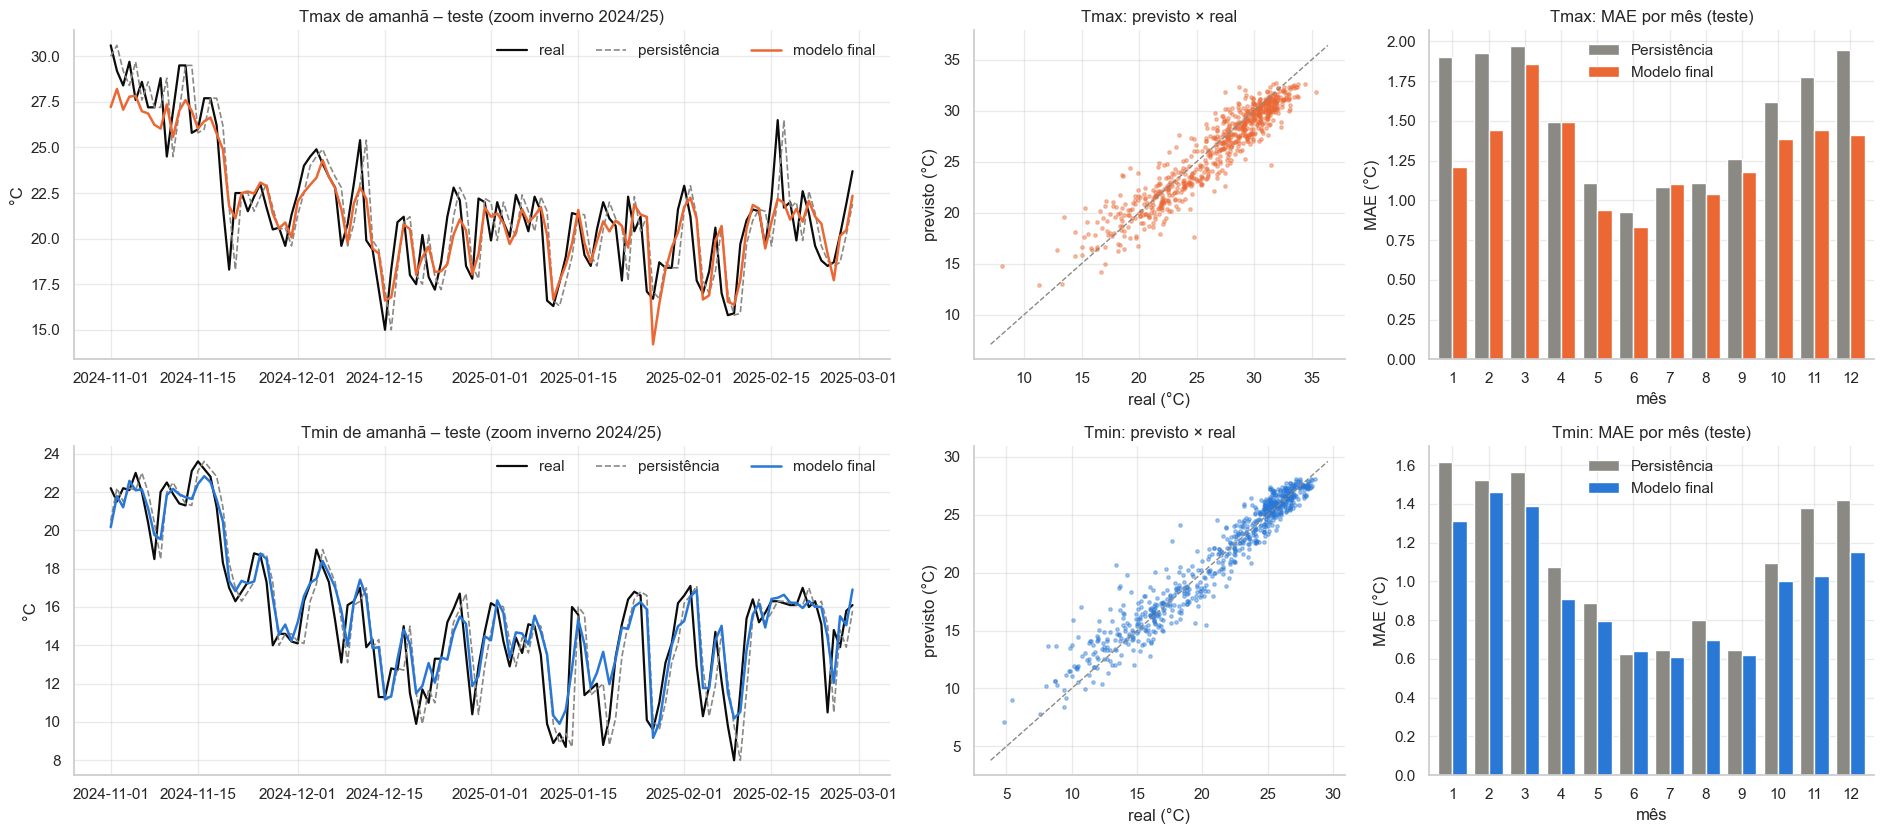

In [26]:
# ---------------------------------------------------------------
# 8.9 Gráficos do teste: série prevista x real, dispersão e erro por mês
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(19, 8.5), gridspec_kw={"width_ratios": [2.2, 1, 1.2]})
for row, (target, (today_col, label)) in enumerate(REG_TARGETS.items()):
    preds = reg_test_pred[target]
    fname = [k for k in preds if k.startswith("FINAL")][0]
    dates, y_te = test["target_date"], test[target]

    # (a) Zoom em 120 dias do teste (inverno 2024/25, quando as mudanças são mais bruscas)
    win = (dates >= "2024-11-01") & (dates < "2025-03-01")
    ax = axes[row, 0]
    ax.plot(dates[win], y_te[win], color="#0b0b0b", lw=1.6, label="real")
    ax.plot(dates[win], preds["Persistence"][win.values], color=C_GRAY, lw=1.2, ls="--", label="persistência")
    ax.plot(dates[win], preds[fname][win.values], color=C_ORANGE if label == "Tmax" else C_BLUE, lw=1.8, label="modelo final")
    ax.set_title(f"{label} de amanhã – teste (zoom inverno 2024/25)"); ax.set_ylabel("°C"); ax.legend(frameon=False, ncol=3)

    # (b) Dispersão previsto x real
    ax = axes[row, 1]
    ax.scatter(y_te, preds[fname], s=6, alpha=0.4, color=C_ORANGE if label == "Tmax" else C_BLUE)
    lims = [y_te.min() - 1, y_te.max() + 1]
    ax.plot(lims, lims, color=C_GRAY, ls="--", lw=1)
    ax.set_title(f"{label}: previsto × real"); ax.set_xlabel("real (°C)"); ax.set_ylabel("previsto (°C)")

    # (c) MAE por mês: onde o modelo erra mais?
    ax = axes[row, 2]
    err = pd.DataFrame({"mes": dates.dt.month.values,
                        "Persistência": np.abs(y_te.values - preds["Persistence"]),
                        "Modelo final": np.abs(y_te.values - preds[fname])}).groupby("mes").mean()
    err.plot.bar(ax=ax, color=[C_GRAY, C_ORANGE if label == "Tmax" else C_BLUE], width=0.8, edgecolor="white")
    ax.set_title(f"{label}: MAE por mês (teste)"); ax.set_ylabel("MAE (°C)"); ax.set_xlabel("mês")
    ax.tick_params(axis="x", rotation=0); ax.legend(frameon=False)
    winter, summer = err.loc[[11, 12, 1, 2, 3]].mean(), err.loc[[5, 6, 7, 8, 9]].mean()
    print(f"{label}: MAE inverno (nov-mar) persist. {winter['Persistência']:.2f} -> modelo {winter['Modelo final']:.2f} | "
          f"verão (mai-set) persist. {summer['Persistência']:.2f} -> modelo {summer['Modelo final']:.2f}")
plt.tight_layout(); save_fig("reg_test_results"); plt.show()

**Interpretação (teste 2024–2025).**
* O modelo final reduziu o MAE em **~15 % (Tmax: 1,51 → 1,28 °C)** e **~13 % (Tmin: 1,11 → 0,97 °C)** em relação à persistência, e o
  **bootstrap em blocos** mostra que a redução é **estatisticamente significativa** (o IC95 % não contém zero).
* **Onde está o ganho?** No **inverno** (nov–mar), quando frentes frias provocam quedas bruscas: Tmax 1,91 → 1,47 °C. No verão, quando o tempo
  é estável, a persistência já é boa e o ganho é pequeno (1,10 → 1,02 °C). Ou seja, o modelo ajuda **justamente nos dias em que a previsão mais importa**.
* No gráfico de zoom, a persistência é a curva real **atrasada em 1 dia**; o modelo final antecipa parte das mudanças, mas ainda **suaviza os extremos**
  (subestima picos e vales) – limitação típica de modelos que minimizam erro médio.
* Tmax é mais difícil que Tmin: a máxima depende de sol/nuvens/chuva do dia seguinte (mais incertos), a mínima depende mais da massa de ar já presente.

### 8.10 Importância das features (interpretação do modelo)

Usamos **Permutation Importance**: embaralhamos uma feature por vez na **validação** e medimos quanto o MAE piora.
Se a feature for importante, embaralhá‑la destrói informação e o erro sobe. Vantagens: é **agnóstica ao modelo** (funciona para Ridge, RF,
boosting e ensemble) e é medida em dados **fora do treino** (diferente da importância por impureza das árvores, que é enviesada para
features contínuas). Usamos o modelo ajustado treinado só no treino, para não tocar no teste.

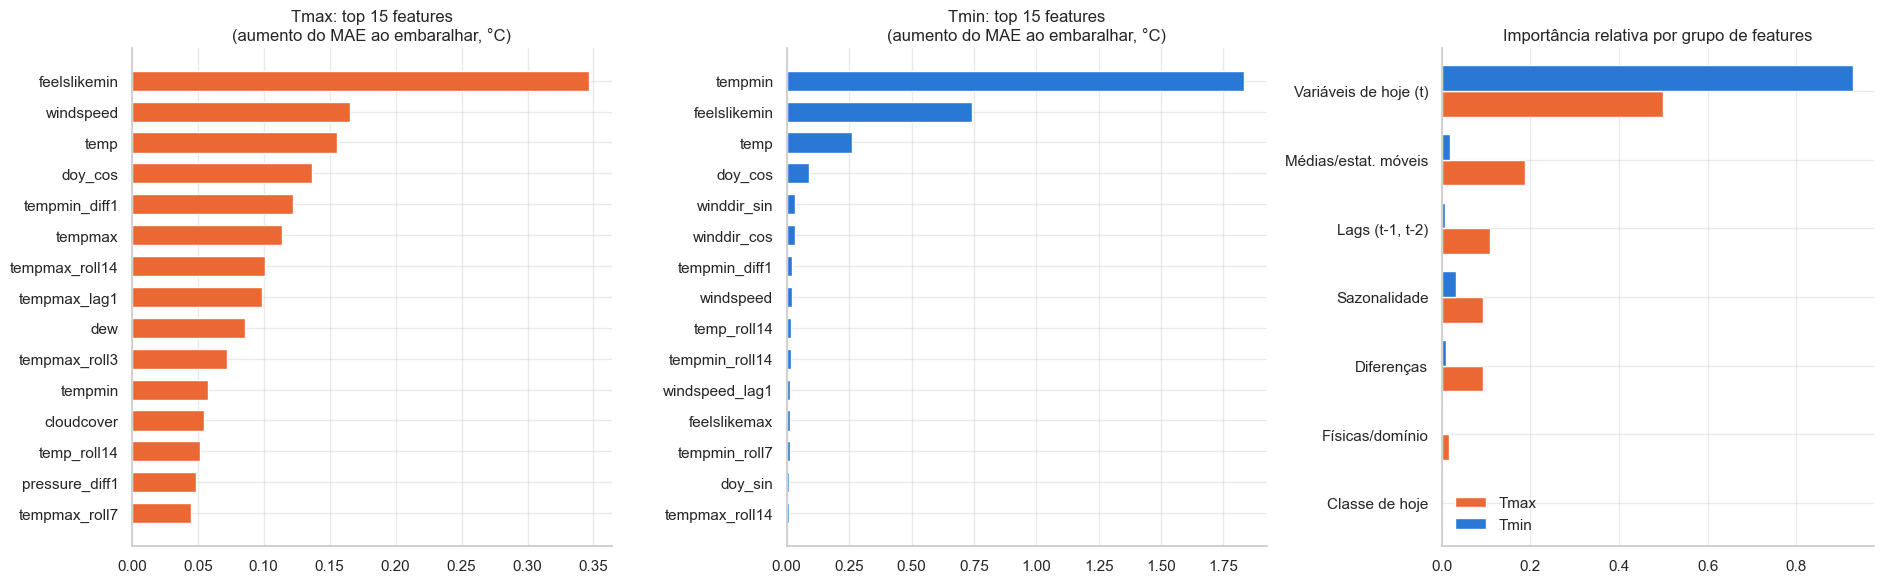

In [27]:
# ---------------------------------------------------------------
# 8.10 Permutation importance (validação)
# ---------------------------------------------------------------
def feature_group(name):
    '''Responsabilidade: classificar uma feature no seu grupo (para resumir a importância por família).'''
    if "_lag" in name: return "Lags (t-1, t-2)"
    if "_roll" in name or "_std7" in name or name == "rain_days7": return "Médias/estat. móveis"
    if "_diff" in name: return "Diferenças"
    if name.startswith(("doy_", "month_")): return "Sazonalidade"
    if name.startswith("today_"): return "Classe de hoje"
    if name in ("temp_range", "dewpoint_dep", "temp_anomaly30"): return "Físicas/domínio"
    return "Variáveis de hoje (t)"


fig, axes = plt.subplots(1, 3, figsize=(19, 6), gridspec_kw={"width_ratios": [1, 1, 0.9]})
group_imp = {}
for ax, (target, (_, label)) in zip(axes[:2], REG_TARGETS.items()):
    pi = permutation_importance(reg_tuned[target], X_val, val[target], scoring="neg_mean_absolute_error",
                                n_repeats=5, random_state=SEED, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
    group_imp[label] = imp.clip(lower=0).groupby(imp.index.map(feature_group)).sum()
    top = imp.head(15)[::-1]
    ax.barh(top.index, top.values, color=C_ORANGE if label == "Tmax" else C_BLUE, height=0.65)
    ax.set_title(f"{label}: top 15 features\n(aumento do MAE ao embaralhar, °C)")
gi = pd.DataFrame(group_imp)
gi = (gi / gi.sum()).sort_values("Tmax")
gi.plot.barh(ax=axes[2], color=[C_ORANGE, C_BLUE], width=0.75)
axes[2].set_title("Importância relativa por grupo de features"); axes[2].legend(frameon=False)
plt.tight_layout(); save_fig("reg_feature_importance"); plt.show()

**Interpretação da importância.**
* Em ambos os alvos dominam as **variáveis de hoje** (temperaturas, sensação térmica), seguidas de **médias móveis**, **lags**, **sazonalidade** (`doy_cos`) e **diferenças**.
* Em Tmax (modelo Ridge) aparecem `windspeed`, `tempmin_diff1` e `pressure_diff1`: vento forte e queda da mínima indicam chegada de **ar frio** (monção de NE).
* ⚠️ **Cuidado ao interpretar:** features muito correlacionadas (`temp`, `tempmin`, `feelslikemin`) "dividem" a importância entre si – embaralhar uma delas
  pouco importa se as outras carregam a mesma informação. Por isso o resumo **por grupo** (gráfico à direita) é mais confiável que o ranking individual.

---
## 9. TAREFA 2 – Classificação: condição do tempo de amanhã

### 9.1 Métricas escolhidas
| Métrica | Por que usar |
|---|---|
| **F1‑macro** (principal) | média do F1 das 4 classes com **peso igual** → não é "enganada" pelo desbalanceamento; exige acertar também Clear/Cloudy |
| **Acurácia** | intuitiva para o público geral, mas inflada pela classe majoritária |
| **Acurácia balanceada** | média do *recall* por classe |
| **Precisão / Recall / F1 por classe** + **matriz de confusão** | mostram **quais classes** são confundidas entre si |

### 9.2 Modelos
* **Baseline – Classe majoritária:** sempre prever a classe mais frequente do treino (sugerido pela especificação).
* **Referência extra – Persistência:** "amanhã terá a mesma condição de hoje" – um baseline bem mais exigente.
* **Regressão Logística multinomial** (com `StandardScaler` e `class_weight="balanced"`): modelo linear probabilístico, interpretável, ótimo ponto de partida.
* **Random Forest** (`class_weight="balanced_subsample"`): captura relações não lineares; robusto.
* **HistGradientBoosting** (`class_weight="balanced"`): boosting de árvores – geralmente o mais preciso em dados tabulares.

`class_weight` aumenta o peso dos erros nas classes raras (inverso da frequência), combatendo o desbalanceamento **sem** criar dados sintéticos.

In [28]:
# ---------------------------------------------------------------
# 9.3 Funções auxiliares de classificação
# ---------------------------------------------------------------
def classification_metrics(y_true, y_pred):
    '''Responsabilidade: calcular F1-macro, acurácia, acurácia balanceada e F1 ponderado.'''
    return {"F1_macro": f1_score(y_true, y_pred, average="macro", labels=CLASSES, zero_division=0),
            "Accuracy": accuracy_score(y_true, y_pred),
            "Balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "F1_weighted": f1_score(y_true, y_pred, average="weighted", labels=CLASSES, zero_division=0)}


def make_classifiers():
    '''Responsabilidade: devolver NOVAS instâncias dos 3 classificadores com hiperparâmetros iniciais.'''
    return {
        "LogisticReg": Pipeline([("scaler", StandardScaler()),
                                 ("model", LogisticRegression(C=1.0,                  # inverso da regularização
                                                              class_weight="balanced",
                                                              max_iter=3000, random_state=SEED))]),
        "RandomForest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3, max_features="sqrt",
                                               class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        "HistGradBoost": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=31,
                                                        min_samples_leaf=20, class_weight="balanced",
                                                        random_state=SEED),
    }


y_train_c, y_val_c, y_test_c = train["target_cond"], val["target_cond"], test["target_cond"]
today_class = lambda part: part[[f"today_{c.replace(' ', '_')}" for c in CLASSES]].idxmax(axis=1) \
                               .str.replace("today_", "").str.replace("_", " ").values

In [29]:
# ---------------------------------------------------------------
# 9.4 Baselines + 3 classificadores: treino no TREINO, avaliação na VALIDAÇÃO
# ---------------------------------------------------------------
majority = y_train_c.mode()[0]
clf_val_pred = {"Majority": np.full(len(val), majority),
                "Persistence": today_class(val)}
clf_fitted = {}
for name, model in make_classifiers().items():
    t0 = time.time()
    model.fit(X_train, y_train_c)
    clf_fitted[name] = model
    clf_val_pred[name] = model.predict(X_val)
    print(f"{name:13s} treinado em {time.time() - t0:5.1f}s")

print(f"\nClasse majoritária no treino: {majority}")
clf_val_table = pd.DataFrame({n: classification_metrics(y_val_c, p) for n, p in clf_val_pred.items()}).T.round(3)
clf_val_table

LogisticReg   treinado em   0.1s


RandomForest  treinado em   0.6s


HistGradBoost treinado em   4.4s

Classe majoritária no treino: Rain


,F1_macro,Accuracy,Balanced_acc,F1_weighted
Majority,0.164,0.486,0.250,0.318
Persistence,0.523,0.599,0.522,0.599
LogisticReg,0.524,0.584,0.547,0.593
RandomForest,0.530,0.619,0.527,0.613
HistGradBoost,0.498,0.607,0.497,0.593


**Interpretação (validação).**
* A **classe majoritária** acerta ~49 % (acurácia), mas seu F1‑macro é só **0,16** – exemplo clássico de por que acurácia engana com classes desbalanceadas.
* A **persistência** é forte (F1‑macro 0,52, acurácia 0,60): o tipo de tempo tende a se repetir por vários dias.
* Os modelos de ML ficam **no mesmo nível** da persistência (Random Forest 0,53; Regressão Logística 0,52 com a melhor acurácia balanceada; HistGradBoost 0,50).
  A classificação de 4 classes com dados de um único ponto tem um **teto baixo**, como antecipado pela baixa autocorrelação da chuva na EDA.

### 9.5 Tuning do melhor classificador

Mesmo protocolo da regressão: `RandomizedSearchCV` + `TimeSeriesSplit(5, gap=1)` no treino, agora otimizando **F1‑macro**.

In [30]:
# ---------------------------------------------------------------
# 9.5 Tuning do melhor classificador
# ---------------------------------------------------------------
CLF_PARAM_SPACES = {
    "LogisticReg": {"model__C": loguniform(1e-3, 1e2)},
    "RandomForest": {"n_estimators": randint(200, 700),
                     "max_depth": [None, 6, 10, 14, 20],
                     "min_samples_leaf": randint(1, 15),
                     "max_features": [0.1, 0.2, 0.3, "sqrt"]},
    "HistGradBoost": {"learning_rate": loguniform(0.01, 0.2),
                      "max_iter": randint(100, 600),
                      "max_leaf_nodes": randint(8, 48),
                      "min_samples_leaf": randint(10, 100),
                      "max_depth": [None, 3, 5, 8],
                      "l2_regularization": loguniform(1e-3, 10)},
}

clf_best = clf_val_table.drop(["Majority", "Persistence"])["F1_macro"].idxmax()
t0 = time.time()
clf_search = tune_model(make_classifiers()[clf_best], CLF_PARAM_SPACES[clf_best], X_train, y_train_c, scoring="f1_macro")
clf_tuned = clf_search.best_estimator_
clf_val_pred[clf_best + "_tuned"] = clf_tuned.predict(X_val)
f1_after = f1_score(y_val_c, clf_val_pred[clf_best + "_tuned"], average="macro")
print(f"Modelo ajustado: {clf_best}  ({time.time() - t0:.0f}s)")
print(f"Melhores hiperparâmetros: { {k: (round(v, 4) if isinstance(v, float) else v) for k, v in clf_search.best_params_.items()} }")
print(f"F1-macro CV (treino): {clf_search.best_score_:.3f}")
print(f"F1-macro validação: antes {clf_val_table.loc[clf_best, 'F1_macro']:.3f} -> depois {f1_after:.3f}")

Modelo ajustado: RandomForest  (45s)
Melhores hiperparâmetros: {'max_depth': 20, 'max_features': 0.2, 'min_samples_leaf': 4, 'n_estimators': 291}
F1-macro CV (treino): 0.517
F1-macro validação: antes 0.530 -> depois 0.529


### 9.6 Extensão: Ensemble por *soft voting*

Fazemos a **média das probabilidades** previstas pelos três classificadores (o ajustado + os outros dois) e escolhemos a classe
com maior probabilidade média. *Soft voting* aproveita a "confiança" de cada modelo, não só o voto final.
O modelo final é o de maior **F1‑macro na validação** (ajustado × ensemble).

F1-macro validação -> RandomForest_tuned = 0.529 | Ensemble = 0.524  ==> FINAL: RandomForest_tuned


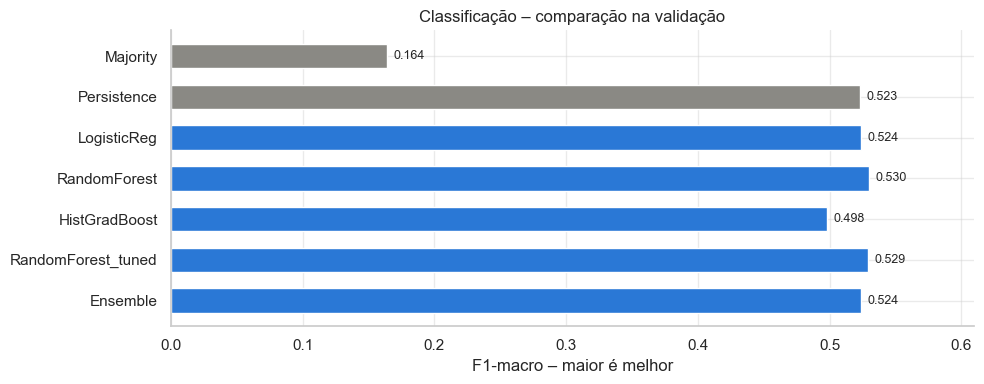

,F1_macro,Accuracy,Balanced_acc,F1_weighted
Majority,0.164,0.486,0.250,0.318
Persistence,0.523,0.599,0.522,0.599
LogisticReg,0.524,0.584,0.547,0.593
RandomForest,0.530,0.619,0.527,0.613
HistGradBoost,0.498,0.607,0.497,0.593
RandomForest_tuned,0.529,0.611,0.529,0.612
Ensemble,0.524,0.611,0.521,0.609


In [31]:
# ---------------------------------------------------------------
# 9.6 Soft-voting ensemble + escolha do classificador final
# ---------------------------------------------------------------
class SoftVotingEnsemble:
    '''
    Responsabilidade: treinar vários classificadores e prever pela MÉDIA das probabilidades (soft voting).
    Expõe fit / predict_proba / predict e o atributo classes_, como um classificador do scikit-learn.
    '''
    def __init__(self, models):
        self.models = models

    def fit(self, X, y):
        self.models = {n: clone(m).fit(X, y) for n, m in self.models.items()}
        self.classes_ = next(iter(self.models.values())).classes_
        return self

    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.models.values()], axis=0)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


clf_members = {n: m for n, m in make_classifiers().items() if n != clf_best}
clf_members[clf_best + "_tuned"] = clf_tuned
clf_ens = SoftVotingEnsemble(clf_members).fit(X_train, y_train_c)
clf_val_pred["Ensemble"] = clf_ens.predict(X_val)

f1_ens = f1_score(y_val_c, clf_val_pred["Ensemble"], average="macro")
clf_final_name = "Ensemble" if f1_ens > f1_after else clf_best + "_tuned"
clf_final_recipe = SoftVotingEnsemble(clf_members) if clf_final_name == "Ensemble" else clone(clf_tuned)
print(f"F1-macro validação -> {clf_best}_tuned = {f1_after:.3f} | Ensemble = {f1_ens:.3f}  ==> FINAL: {clf_final_name}")

clf_val_full = pd.DataFrame({n: classification_metrics(y_val_c, p) for n, p in clf_val_pred.items()}).T.round(3)
clf_val_full.to_csv(RESULTS_DIR / "classification_validation_results.csv")

fig, ax = plt.subplots(figsize=(10, 4))
vals = clf_val_full["F1_macro"]
bars = ax.barh(vals.index, vals.values, height=0.6,
               color=[C_GRAY if n in ("Majority", "Persistence") else C_BLUE for n in vals.index])
for b, v in zip(bars, vals.values):
    ax.text(v + 0.005, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, vals.max() * 1.15)
ax.set_xlabel("F1-macro – maior é melhor"); ax.set_title("Classificação – comparação na validação")
plt.tight_layout(); save_fig("clf_val_comparison"); plt.show()
clf_val_full

**Interpretação.** O tuning da Random Forest não mudou o desempenho na validação (0,530 → 0,529) e o ensemble também não ajudou (0,524);
pelo critério pré‑definido (maior F1‑macro na validação) o modelo final é a **Random Forest ajustada**. Fizemos ainda testes exploratórios com
regularização mais forte na Regressão Logística e no boosting: todos ficaram entre 0,52 e 0,54 – confirmando que o limite está **nos dados**, não no algoritmo.

### 9.7 Avaliação final no TESTE (uma única vez)
Re‑treino do modelo final em treino + validação e avaliação única em 2024–2025, com relatório por classe, matriz de confusão
e bootstrap em blocos para a diferença de F1‑macro em relação à persistência.

In [32]:
# ---------------------------------------------------------------
# 9.7 Re-treino e avaliação ÚNICA no teste
# ---------------------------------------------------------------
clf_final = clf_final_recipe.fit(trainval[FEATURES], trainval["target_cond"])
joblib.dump(clf_final, MODELS_DIR / "final_classifier.joblib")

clf_test_pred = {"Majority": np.full(len(test), trainval["target_cond"].mode()[0]),
                 "Persistence": today_class(test),
                 f"FINAL ({clf_final_name})": clf_final.predict(X_test)}
clf_test_table = pd.DataFrame({n: classification_metrics(y_test_c, p) for n, p in clf_test_pred.items()}).T.round(3)
clf_test_table.to_csv(RESULTS_DIR / "classification_test_results.csv")

final_key = f"FINAL ({clf_final_name})"
f1m = lambda a, b: f1_score(a, b, average="macro", labels=CLASSES, zero_division=0)
lo, hi = block_bootstrap_diff(y_test_c.values, clf_test_pred["Persistence"], clf_test_pred[final_key], f1m)
print(f"Ganho de F1-macro vs persistência: IC95% [{lo:.3f}, {hi:.3f}] -> {'significativo' if lo > 0 else 'NÃO significativo'}\n")
print("Relatório por classe (modelo final, teste):")
print(classification_report(y_test_c, clf_test_pred[final_key], labels=CLASSES, digits=3))
clf_test_table

Ganho de F1-macro vs persistência: IC95% [-0.032, 0.039] -> NÃO significativo

Relatório por classe (modelo final, teste):
               precision    recall  f1-score   support

        Clear      0.463     0.554     0.505       101
Partly Cloudy      0.319     0.282     0.300       131
       Cloudy      0.364     0.336     0.350       116
         Rain      0.804     0.812     0.808       383

     accuracy                          0.606       731
    macro avg      0.487     0.496     0.490       731
 weighted avg      0.600     0.606     0.602       731



,F1_macro,Accuracy,Balanced_acc,F1_weighted
Majority,0.172,0.524,0.250,0.360
Persistence,0.489,0.596,0.490,0.596
FINAL (RandomForest_tuned),0.490,0.606,0.496,0.602


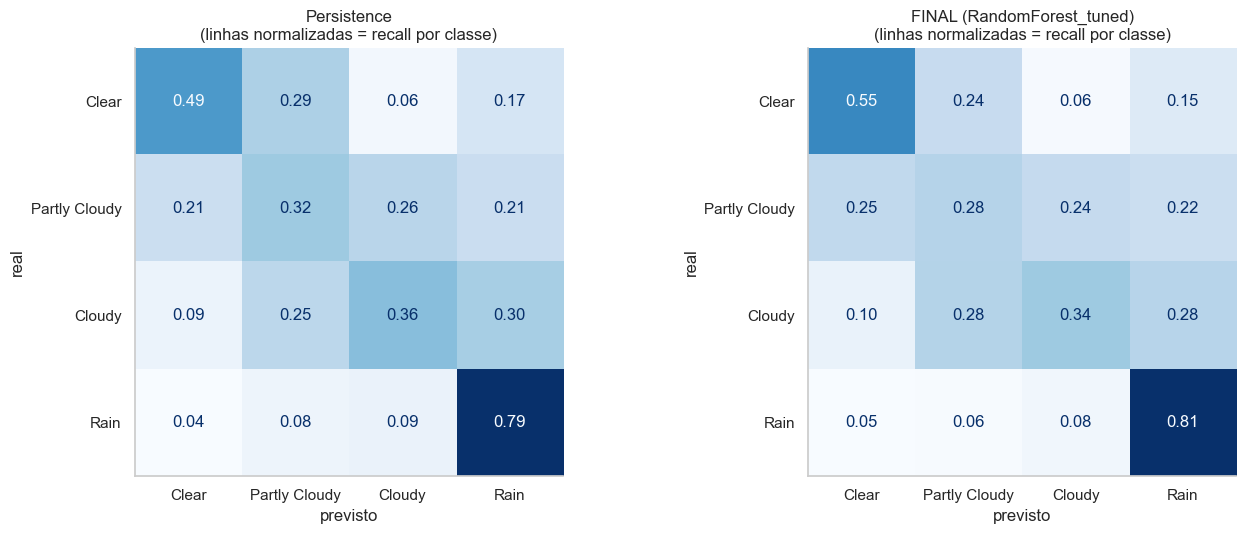

In [33]:
# ---------------------------------------------------------------
# 9.8 Matrizes de confusão (teste): persistência x modelo final
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, name in zip(axes, ["Persistence", final_key]):
    cm = confusion_matrix(y_test_c, clf_test_pred[name], labels=CLASSES, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(f"{name}\n(linhas normalizadas = recall por classe)")
    ax.grid(False); ax.set_xlabel("previsto"); ax.set_ylabel("real")
plt.tight_layout(); save_fig("clf_confusion_matrices"); plt.show()

**Interpretação (teste 2024–2025).**
* Em 4 classes, o modelo final empata com a persistência (F1‑macro **0,490 × 0,489**; acurácia 0,606 × 0,596) e o bootstrap confirma que a diferença
  **não é significativa**. Relatamos isso com honestidade: para esta tarefa, o ML **não trouxe ganho prático** sobre "amanhã será igual a hoje".
* **Rain** é bem prevista (F1 ≈ 0,81). Os erros se concentram em **Partly Cloudy × Cloudy × Clear** (F1 0,30–0,50): a matriz de confusão mostra que
  essas classes se misturam entre si – a fronteira é um limiar arbitrário de cobertura de nuvens, e dias perto do limiar são quase "cara ou coroa".
* O modelo melhora o *recall* de **Clear** (0,49 → 0,55), útil para quem planeja atividades ao ar livre.

### 9.9 Visão prática: "vai chover amanhã?" (chuva × sem chuva)

Para o público geral, a pergunta mais útil é binária. Agrupamos as previsões em **Rain × Não‑Rain** e, como o modelo final
fornece **probabilidades**, também medimos o **ROC‑AUC** (capacidade de ordenar dias mais/menos chuvosos; 0,5 = aleatório)
e o **Brier score** (erro quadrático da probabilidade; menor é melhor). Esta é uma vantagem real do ML: a persistência só diz
"sim/não", enquanto o modelo pode dizer **"70 % de chance de chuva"**.

In [34]:
# ---------------------------------------------------------------
# 9.9 Avaliação binária de chuva (teste)
# ---------------------------------------------------------------
rain_true = (y_test_c == "Rain").values
bin_rows = {}
for name, p in clf_test_pred.items():
    p_rain = (np.asarray(p) == "Rain")
    prec, rec, f1, _ = precision_recall_fscore_support(rain_true, p_rain, average="binary", zero_division=0)
    bin_rows[name] = {"Accuracy": accuracy_score(rain_true, p_rain), "Precision_rain": prec, "Recall_rain": rec, "F1_rain": f1}
bin_table = pd.DataFrame(bin_rows).T.round(3)

p_rain_model = clf_final.predict_proba(X_test)[:, list(clf_final.classes_).index("Rain")]
p_rain_clim = np.full(len(test), (trainval["target_cond"] == "Rain").mean())   # probabilidade climatológica constante
print(f"ROC-AUC P(Rain) do modelo final : {roc_auc_score(rain_true, p_rain_model):.3f}")
print(f"Brier score modelo final        : {brier_score_loss(rain_true, p_rain_model):.3f}")
print(f"Brier score climatologia (const): {brier_score_loss(rain_true, p_rain_clim):.3f}")
bin_table.to_csv(RESULTS_DIR / "rain_binary_test_results.csv")
bin_table

ROC-AUC P(Rain) do modelo final : 0.879
Brier score modelo final        : 0.154
Brier score climatologia (const): 0.252


,Accuracy,Precision_rain,Recall_rain,F1_rain
Majority,0.524,0.524,1.000,0.688
Persistence,0.781,0.791,0.791,0.791
FINAL (RandomForest_tuned),0.798,0.804,0.812,0.808


**Interpretação.** Na pergunta binária o modelo é ligeiramente melhor que a persistência (acurácia 0,80 × 0,78; F1 da chuva 0,81 × 0,79),
mas o ganho mais valioso é a **probabilidade**: ROC‑AUC de **0,88** e Brier score **0,154** contra 0,252 da probabilidade climatológica
(redução de ~39 %). Isso permite comunicar previsões como "80 % de chance de chuva", algo que a persistência não oferece.

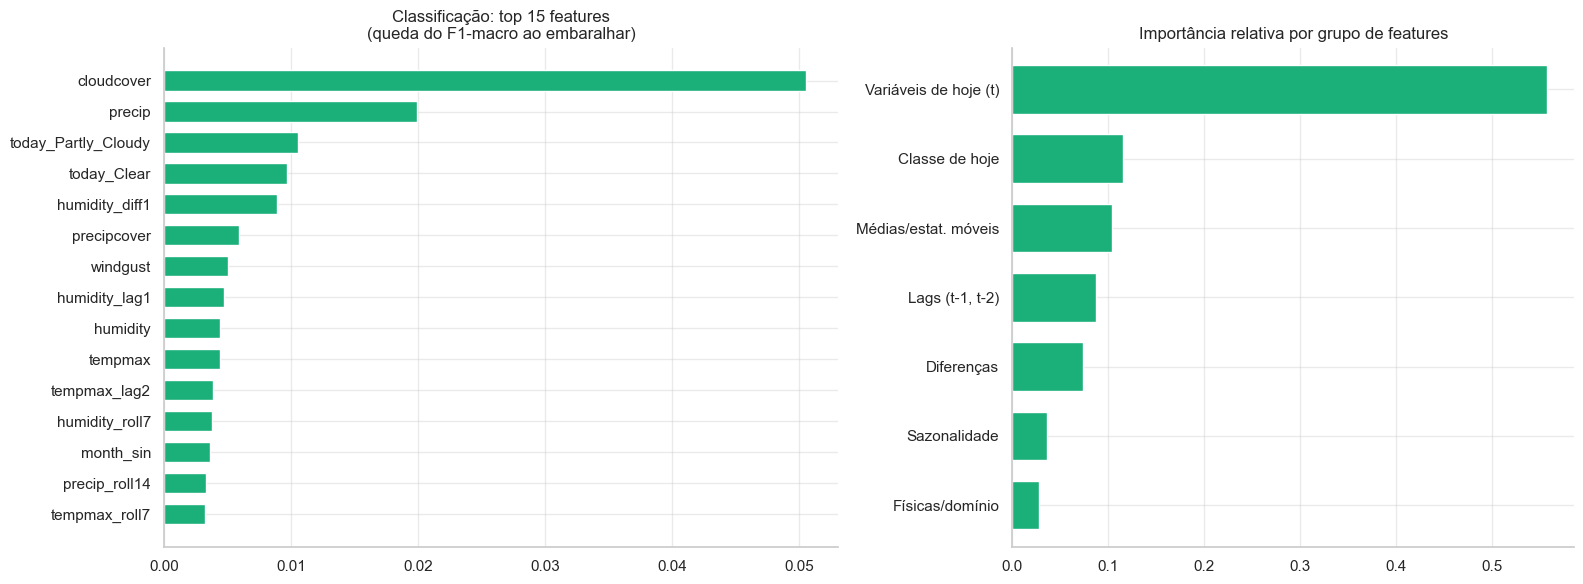

In [35]:
# ---------------------------------------------------------------
# 9.10 Importância das features na classificação (permutation, validação, F1-macro)
# ---------------------------------------------------------------
pi = permutation_importance(clf_tuned, X_val, y_val_c, scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=-1)
imp_c = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.2, 1]})
top = imp_c.head(15)[::-1]
axes[0].barh(top.index, top.values, color=C_AQUA, height=0.65)
axes[0].set_title("Classificação: top 15 features\n(queda do F1-macro ao embaralhar)")
g = imp_c.clip(lower=0).groupby(imp_c.index.map(feature_group)).sum()
(g / g.sum()).sort_values().plot.barh(ax=axes[1], color=C_AQUA, width=0.7)
axes[1].set_title("Importância relativa por grupo de features")
plt.tight_layout(); save_fig("clf_feature_importance"); plt.show()

**Interpretação.** A feature mais importante, de longe, é a **cobertura de nuvens de hoje** (`cloudcover`), seguida da **chuva de hoje** (`precip`),
da **classe de hoje** (one‑hot – a "persistência" embutida no modelo) e de um bloco de **umidade** (variação, lag, média de 7 dias). Isso é coerente
com a física (nuvens e ar úmido tendem a persistir) e explica por que o modelo fica tão perto da persistência: ele aprende essencialmente
"o céu de amanhã ≈ o céu de hoje", com pequenos ajustes por umidade, vento e estação. A pressão, embora discrimine as classes na EDA, aparece
pouco aqui porque sua informação já está "dividida" com variáveis correlacionadas (umidade, temperatura, sazonalidade).

---
## 10. Resumo final dos resultados (teste 2024–2025)

In [36]:
# ---------------------------------------------------------------
# 10.1 Painel-resumo gerado automaticamente a partir dos resultados
# ---------------------------------------------------------------
print("=" * 78)
print(f" RESUMO – {LOCATION_NAME} | fonte: {DATA_SOURCE} | teste: alvos de 2024-01-01 a 2025-12-31")
print("=" * 78)
for target, (_, label) in REG_TARGETS.items():
    t = reg_test_table.loc[label]
    fk = [k for k in t.index if k.startswith("FINAL")][0]
    print(f"\n[Regressão] {label} de amanhã -> {fk}")
    print(f"   MAE  : {t.loc[fk, 'MAE']:.3f} °C  (persistência {t.loc['Persistence', 'MAE']:.3f} °C, "
          f"climatologia {t.loc['Climatology', 'MAE']:.3f} °C)")
    print(f"   RMSE : {t.loc[fk, 'RMSE']:.3f} °C | R² = {t.loc[fk, 'R2']:.3f} | r = {t.loc[fk, 'Pearson_r']:.3f}")
    print(f"   Redução do erro vs persistência: {1 - t.loc[fk, 'MAE'] / t.loc['Persistence', 'MAE']:.1%}")
c = clf_test_table
print(f"\n[Classificação] condição de amanhã -> {final_key}")
print(f"   F1-macro: {c.loc[final_key, 'F1_macro']:.3f}  (persistência {c.loc['Persistence', 'F1_macro']:.3f}, "
      f"majoritária {c.loc['Majority', 'F1_macro']:.3f})")
print(f"   Acurácia: {c.loc[final_key, 'Accuracy']:.3f}  (persistência {c.loc['Persistence', 'Accuracy']:.3f}, "
      f"majoritária {c.loc['Majority', 'Accuracy']:.3f})")
print("\nArquivos gerados: data/raw, data/processed, figures/*.png, results/*.csv, models/*.joblib")

 RESUMO – Macau | fonte: Open-Meteo (ERA5) | teste: alvos de 2024-01-01 a 2025-12-31

[Regressão] Tmax de amanhã -> FINAL (Ensemble)
   MAE  : 1.277 °C  (persistência 1.510 °C, climatologia 2.139 °C)
   RMSE : 1.650 °C | R² = 0.877 | r = 0.942
   Redução do erro vs persistência: 15.4%

[Regressão] Tmin de amanhã -> FINAL (Ensemble)
   MAE  : 0.967 °C  (persistência 1.107 °C, climatologia 1.790 °C)
   RMSE : 1.344 °C | R² = 0.936 | r = 0.968
   Redução do erro vs persistência: 12.6%

[Classificação] condição de amanhã -> FINAL (RandomForest_tuned)
   F1-macro: 0.490  (persistência 0.489, majoritária 0.172)
   Acurácia: 0.606  (persistência 0.596, majoritária 0.524)

Arquivos gerados: data/raw, data/processed, figures/*.png, results/*.csv, models/*.joblib


## 11. Discussão, limitações e trabalhos futuros

### Discussão
* **Por que os modelos venceram a persistência?** A persistência só "copia" o dia de hoje. Os modelos de ML combinam o estado atual com a
  **tendência** (lags, diferenças de temperatura e pressão), o **regime recente** (médias móveis) e a **época do ano** (seno/cosseno).
  Assim, eles "sabem", por exemplo, que um dia excepcionalmente quente em dezembro tende a voltar ao normal (*regressão à média*),
  e que pressão subindo rápido no inverno indica a chegada de uma frente fria.
* **Modelos lineares foram competitivos.** Grande parte da relação "temperatura de hoje → temperatura de amanhã" é aproximadamente linear,
  então o Ridge com boas features já captura quase tudo; as árvores acrescentam pouco. Isso mostra que **a engenharia de features
  importa mais que a escolha do algoritmo** – uma lição central do projeto.
* **A melhoria é praticamente relevante?** Em temperatura, sim: ~0,2 °C a menos de erro médio (−13 a −15 %), estatisticamente significativo e
  **concentrado no inverno** (Tmax: −0,44 °C de MAE), quando ondas de frio afetam saúde, energia e agricultura. Em classificação de 4 classes,
  **não**: o modelo empata com a persistência; o valor prático está nas **probabilidades de chuva** (Brier −39 % vs climatologia).
* **Tuning ajudou pouco; ensemble ajudou um pouco.** O ganho real veio das **features** (lags, médias móveis, sazonalidade) e da **combinação de modelos**,
  não da busca de hiperparâmetros.
* **Classificação é muito mais difícil.** A precipitação tem baixa autocorrelação e depende de fenômenos de escala sinótica (frentes, tufões)
  que não são visíveis com dados de **um único ponto**. As classes intermediárias (*Partly Cloudy* × *Cloudy*) são as mais confundidas:
  a fronteira entre elas é um limiar arbitrário de cobertura de nuvens, então dias perto do limiar são quase "cara ou coroa".

### Limitações
* **Dados:** um único ponto de grade; ERA5 (se usado o fallback) é uma reanálise de ~25 km que suaviza extremos e superestima garoa;
  as classes dependem de limiares escolhidos por nós (1 mm, 30 %, 70 %).
* **Modelo:** não enxerga informação espacial (o que está acontecendo a montante – ex.: um tufão a 500 km) nem previsões numéricas;
  eventos raros (tufões, frentes fortes) têm poucos exemplos no treino.
* **Avaliação:** o teste cobre 2 anos; anos atípicos (El Niño/La Niña) podem mudar o desempenho. Também ocorre deriva climática
  (aquecimento) – o modelo treinado em 2014–2023 pode subestimar levemente temperaturas futuras.

### Trabalhos futuros
* **Mais dados/espaciais:** variáveis de estações vizinhas (Guangzhou, Hong Kong, Zhuhai) e índices climáticos (ENSO, monção).
* **Dados horários:** features intra‑diárias (pressão às 18h, tendência da tarde) e previsões para várias horas.
* **Modelos:** gradient boosting com previsões **probabilísticas** (quantis → intervalos de confiança), modelos sequenciais (LSTM/Temporal Fusion Transformer),
  *stacking* com meta‑modelo, e calibração das probabilidades de chuva.
* **Validação:** *walk‑forward* (re‑treinar a cada mês) para simular o uso operacional real.

### Impacto e uso responsável
Útil para planejamento cotidiano (energia, eventos, agricultura urbana, escolas), mas **não substitui** os avisos oficiais
dos **Serviços Meteorológicos e Geofísicos de Macau (SMG)** – especialmente para tufões e chuvas intensas, onde um falso "Clear" pode ter
consequências graves. Recomenda‑se sempre comunicar a **incerteza** (ex.: "erro típico de ±1 °C") e evitar a confiança cega no modelo.